# Kit de apresentação — validações da disciplina aplicadas ao problema
### YOLO11s-cls × EfficientNet-B0 · Classificação de tumor cerebral em RM

Este notebook aplica ao nosso problema **as validações vistas na disciplina *Consultoria Especializada em Ciência de Dados 1*** (aulas 01 a 14) e gera as figuras, as legendas e os números para o relatório e os slides. Não usamos o cardápio inteiro: só o que faz sentido para **classificação de imagens com redes já treinadas**. A tabela abaixo mostra o que entrou, em qual figura, e o que ficou de fora e por quê.

| Aula | Conteúdo do slide | Como foi usado aqui | Figura |
|---|---|---|---|
| 01 | Papéis de treino/validação/teste, generalização, gap, viés × variância | Papéis dos conjuntos, estratificação conferida, curva por época com gap | 1, 2 |
| 01 · 14 | Vazamento (tipo A: coluna-gabarito; tipo B: contaminação), checklist antivazamento | Auditoria de **atalhos** com atributos triviais da imagem; quase-duplicatas; checklist | 4, 14 |
| 02 | Matriz de confusão, precisão, recall, F1, F-beta, **dummy que acerta 85%**, `classification_report` | Relatório por classe (macro/ponderado), F2 para tumor, comparação com o classificador burro | 3, 5 |
| 03 | ROC/AUC, PR/AP, **log-loss e sua base de comparação** | ROC e PR lado a lado; log-loss contra a base da prevalência; a penalidade do erro confiante | 6, 7 |
| 05 | Hold-out, estratificação, "um corte só é jogar a moeda", teste tocado uma vez | Estratificação (χ²); decisões só na validação | 1, 9 |
| 06 · 07 | k-fold estratificado, **RepeatedKFold**, média ± desvio, GroupKFold (grupo = paciente) | Estabilidade por dobras estratificadas repetidas do teste; teste limpo como análogo do grupo | 8 |
| 10 | Curva de validação: três regiões, **platô, faixa de empate**, "maldição do vencedor" | Curva por época: melhor época, faixa de empate e otimismo da seleção | 2 |
| 12 · 13 | Comparação pareada, **faixa de empate**, **limiar pelo custo/meta de recall**, **calibração**, auditoria validação → teste | Comparação por dobras; limiar escolhido na validação e medido no teste; reliability e calibração por temperatura | 8, 9, 10 |
| 14 | Reprodutibilidade (semente, Pipeline salvo, model card) | Versões, hash dos pesos, determinismo, `model_card.md` | 14 |
| — | **Mapas de calor (Grad-CAM)** | Mantidos exatamente como já gerados | 12, 13 |

**Não aplicado:** Aula 04 (regressão: não há alvo numérico) · Aulas 08–09 (busca de hiperparâmetros: não houve grid/random search) · Aula 11 (**curva de aprendizado** exige retreinar o modelo com frações do treino — cerca de 13 h só no YOLO em CPU) · Nested CV (já existe teste separado: o próprio slide diz que, nesse caso, "não precisa") · GroupKFold/TimeSeriesSplit (não há id de paciente nem data nas imagens).

**Saídas** (pasta `Kit_Apresentacao/`): `figuras/*.png` · `legendas.json` · `numeros_chave.csv` · `model_card.md` · `reprodutibilidade.json`.

> **Pré-requisito:** ter executado o notebook `Validacao_Completa_YOLO_vs_CNN.ipynb` (cria `resultados_validacao/` com as probabilidades em cache; se não existirem, este notebook as calcula). Execução ≈ 6–10 min em CPU.

In [1]:
!pip install -q torch torchvision ultralytics scikit-learn scipy matplotlib pandas seaborn pyyaml

## 0. Preparação

In [2]:
import io, json, math, time, warnings, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from PIL import Image
from scipy.spatial.distance import cdist
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, log_loss, roc_auc_score, roc_curve, auc,
                             confusion_matrix, matthews_corrcoef)
from ultralytics import YOLO
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "legend.fontsize": 12, "figure.dpi": 100,
                     "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

# ===================== CONFIGURAÇÃO =====================
MODELO, BATCH, NUM_WORKERS, SEED = "efficientnet_b0", 32, 0, 42
DUP_LIM = 2.0          # quase-duplicata = dif. média de pixel <= 2 (miniatura 32x32)
N_ERROS_GRADCAM = 5
CFN, CFP = 5, 1        # custo de um falso negativo e de um falso positivo (exemplo do slide da Aula 12)
META_RECALL = 0.99     # meta de recall para tumor (Aula 12, caminho 1)    # nº máx. de imagens com erro no painel de Grad-CAM
# ========================================================

def achar_base():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "Treinamento_CNN").exists() and (cand / "Treinamento_YOLO").exists(): return cand
    return p
BASE = achar_base()
PASTA_DADOS    = BASE / "Treinamento_CNN" / "Tumor-Cerebral-1"
PASTA_CNN      = BASE / "Treinamento_CNN" / "runs"
PASTA_YOLO_RUN = BASE / "Treinamento_YOLO" / "runs" / "classify" / "runs" / "yolo11s_lung_v2"
PESO_YOLO, PESO_CNN = PASTA_YOLO_RUN / "weights" / "best.pt", PASTA_CNN / f"{MODELO}_best.pt"
RES = BASE / "Validacoes" / "_compartilhado"                  # resultados do notebook de validação completa
KIT = BASE / "Validacoes" / "_anteriores" / "Kit_Apresentacao"; FIG = KIT / "figuras"; FIG.mkdir(parents=True, exist_ok=True)

nec = {"resultados_validacao/": RES, "peso YOLO": PESO_YOLO, "peso CNN": PESO_CNN}
falt = {k: str(v) for k, v in nec.items() if not Path(v).exists()}
if falt: raise FileNotFoundError("Execute antes o notebook Validacao_Completa_YOLO_vs_CNN.ipynb. Faltando: " + json.dumps(falt, ensure_ascii=False, indent=1))

NOME_Y, NOME_C = "YOLO11s-cls", "EfficientNet-B0"; MODELOS = [NOME_Y, NOME_C]
COR = {NOME_Y: "#d95f02", NOME_C: "#1b9e77"}; NOME_S = {"train": "Treino", "val": "Validação", "test": "Teste"}
meta = json.loads((PASTA_CNN / f"{MODELO}_meta.json").read_text(encoding="utf-8")); IMG_SIZE = meta["img_size"]
hist_c = pd.read_csv(PASTA_CNN / f"{MODELO}_historico.csv"); hist_y = pd.read_csv(PASTA_YOLO_RUN / "results.csv"); hist_y.columns = [c.strip() for c in hist_y.columns]
hist_c["lr"] = [0.5 * 3e-4 * (1 + math.cos(math.pi * (e - 1) / meta["epocas_treinadas"])) for e in hist_c["epoca"]]   # reconstruído (cosine)

def selecionar_device():
    if torch.backends.mps.is_available(): return torch.device("mps")
    if torch.cuda.is_available(): return torch.device("cuda")
    return torch.device("cpu")
device = selecionar_device(); torch.manual_seed(SEED)

PRESERVAR = {"12_gradcam_acertos.png", "13_gradcam_erros.png"}   # os 2 mapas de calor aprovados ficam exatamente como estão
LEG = []   # legendas estruturadas (alimentam o documento Word)
def salvar(nome, titulo, mostra, ler, resultado):
    if nome in PRESERVAR and (FIG / nome).exists(): print("preservado (não regenerado):", nome); plt.show()
    else: plt.savefig(FIG / nome, bbox_inches="tight", facecolor="white"); plt.show()
    LEG.append(dict(arquivo=nome, titulo=titulo, mostra=mostra, ler=ler, resultado=resultado)); print("salvo:", nome)
print("Base:", BASE, "| device:", device)

Base: C:\Users\pedro.almeida\Downloads\Trabalho Faculdade | device: cpu


In [3]:
tf_aval = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
PS = {"train": "train", "val": "valid", "test": "test"}
DS = {s: datasets.ImageFolder(PASTA_DADOS / PS[s], tf_aval) for s in PS}; CLASSES = DS["val"].classes; NC = len(CLASSES)
Y = {s: np.array(DS[s].targets) for s in DS}; CAM = {s: [p for p, _ in DS[s].samples] for s in DS}

def criar_cnn():
    m = models.efficientnet_b0(weights=None); m.classifier[1] = nn.Linear(m.classifier[1].in_features, NC); return m
cnn = criar_cnn(); cnn.load_state_dict(torch.load(PESO_CNN, map_location="cpu")); cnn = cnn.to(device).eval()
yolo = YOLO(str(PESO_YOLO)); yolo_net = yolo.model.to(device).eval()
idx_y = [next(k for k, v in yolo.names.items() if v == c) for c in CLASSES]

@torch.no_grad()
def probs_cnn(ds):
    ps = []
    for x, _ in DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS): ps.append(torch.softmax(cnn(x.to(device)), 1).cpu().numpy())
    return np.concatenate(ps)
def probs_yolo(ds):
    c = [p for p, _ in ds.samples]; ps = []
    for i in range(0, len(c), 64):
        for r in yolo.predict(c[i:i+64], imgsz=IMG_SIZE, verbose=False, device=device.type): ps.append(r.probs.data.cpu().numpy()[idx_y])
    return np.array(ps)
def com_cache(chave, fn):
    f = RES / "cache" / f"{chave}.npy"
    if f.exists(): return np.load(f)
    r = fn(); f.parent.mkdir(exist_ok=True); np.save(f, r); return r
sel = lambda p: int(Path(p).stat().st_mtime)
PROB = {m: {} for m in MODELOS}
for s in DS:
    PROB[NOME_C][s] = com_cache(f"cnn_{s}_{sel(PESO_CNN)}_{len(DS[s])}", lambda: probs_cnn(DS[s]))
    PROB[NOME_Y][s] = com_cache(f"yolo_{s}_{sel(PESO_YOLO)}_{len(DS[s])}", lambda: probs_yolo(DS[s]))
PRED = {m: {s: PROB[m][s].argmax(1) for s in DS} for m in MODELOS}
for m in MODELOS: print(m, {NOME_S[s]: round(accuracy_score(Y[s], PRED[m][s]), 4) for s in DS})

# ---- utilidades ----
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - a) / d, (c + a) / d
def ece(y, P, bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y).astype(float); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e
def roc_macro(y, P):
    Yb = np.eye(NC)[y]; f = np.unique(np.concatenate([roc_curve(Yb[:, i], P[:, i])[0] for i in range(NC)]))
    t = np.mean([np.interp(f, *roc_curve(Yb[:, i], P[:, i])[:2]) for i in range(NC)], axis=0); return f, t, auc(f, t)
perda = lambda y, P: -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))
acc = lambda m, s: accuracy_score(Y[s], PRED[m][s])
pp = lambda x: f"{100*x:.1f}%"
def gradcam(net, camada, x, classe=None):
    ativ, grads = [], []
    def fh(mod, inp, out): ativ.append(out); out.register_hook(lambda g: grads.append(g))
    h = camada.register_forward_hook(fh)
    with torch.enable_grad():
        xx = x.clone().requires_grad_(True); net.zero_grad(); out = net(xx); out = out[0] if isinstance(out, (tuple, list)) else out
        c = int(out.argmax(1)) if classe is None else classe; out[0, c].backward()
    h.remove(); a, g = ativ[0].detach(), grads[0].detach(); cm = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cm = F.interpolate(cm, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]; cm = cm / (cm.max() + 1e-8); return cm.cpu().numpy(), c
GC = {NOME_C: (cnn, cnn.features[-1], lambda im: tf_aval(im).unsqueeze(0).to(device)),
      NOME_Y: (yolo_net, yolo_net.model[-2], lambda im: transforms.ToTensor()(im.resize((IMG_SIZE, IMG_SIZE))).unsqueeze(0).to(device))}
NUM = {}   # números-chave

YOLO11s-cls {'Treino': 0.9994, 'Validação': 0.971, 'Teste': 0.9794}
EfficientNet-B0 {'Treino': 0.9996, 'Validação': 0.9884, 'Teste': 0.9912}


In [4]:
import sys, platform, hashlib
from scipy.stats import chi2_contingency
from scipy.optimize import minimize_scalar
from scipy.spatial.distance import cdist
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import fbeta_score, precision_recall_curve, average_precision_score, classification_report
SPL3 = ["train", "val", "test"]; i_nt = CLASSES.index("notumor")
sty = {"ok": ("#c8e6c9", "#1b5e20", "OK"), "atencao": ("#fff3cd", "#7a5b00", "ATENÇÃO"), "falha": ("#ffcdd2", "#b71c1c", "FALHA")}

## 0.1 Quase-duplicatas e atributos triviais das imagens
Preparam duas validações: o **teste limpo** (análogo ao `GroupKFold` por paciente: imagens repetidas não podem estar dos dois lados) e a **auditoria de atalhos** (Aula 14: "uma coluna sozinha com peso enorme"). Cada imagem vira 18 atributos triviais — brilho, contraste, fração de fundo preto, caixa ocupada pelo crânio, bordas e cantos — que **não carregam informação de tumor**.

In [5]:
X32 = {s: np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() for p in CAM[s]]) for s in DS}
nn_d = lambda a, b: (cdist(X32[a], X32[b], "cityblock") / 1024).min(1)
dup_tt, dup_tv, dup_vt = nn_d("test", "train") <= DUP_LIM, nn_d("test", "val") <= DUP_LIM, nn_d("val", "train") <= DUP_LIM
LIMPO_T = ~(dup_tt | dup_tv); NUM["pct_teste_quase_duplicata_treino"] = round(100 * dup_tt.mean(), 1); NUM["imagens_teste_quase_duplicata_treino"] = int(dup_tt.sum())
acc_limpo = {m: accuracy_score(Y["test"][LIMPO_T], PRED[m]["test"][LIMPO_T]) for m in MODELOS}
for m in MODELOS: NUM[f"acc_teste_limpo_{m}"] = round(acc_limpo[m], 4)

FEATN = ["média", "desvio", "p5", "p25", "p50", "p75", "p95", "fração de fundo", "altura do crânio", "largura do crânio", "aspecto", "área ocupada", "borda superior", "borda inferior", "borda esquerda", "borda direita", "canto sup. esq.", "canto sup. dir."]
def feats(path):
    a = np.asarray(Image.open(path).convert("L").resize((256, 256), Image.BILINEAR), dtype=np.float32); fg = a > 8; ys, xs = np.where(fg)
    h, w = (ys.max() - ys.min() + 1, xs.max() - xs.min() + 1) if len(ys) else (0, 0)
    return [a.mean(), a.std(), *np.percentile(a, [5, 25, 50, 75, 95]), (~fg).mean(), h, w, w / max(h, 1), h * w / 65536, a[:8].mean(), a[-8:].mean(), a[:, :8].mean(), a[:, -8:].mean(), np.median(a[:16, :16]), np.median(a[:16, -16:])]
fp = RES / "cache" / f"feats_{sum(len(DS[s]) for s in DS)}.npz"
if fp.exists(): FT = dict(np.load(fp))
else:
    FT = {s: np.array([feats(p) for p in CAM[s]]) for s in SPL3}; fp.parent.mkdir(exist_ok=True); np.savez(fp, **FT)
print({s: FT[s].shape for s in FT})

{'train': (4819, 18), 'val': (1379, 18), 'test': (681, 18)}


## Figura 1 — Papéis dos conjuntos e estratificação (Aulas 01 e 05)
Treino **aprende**, validação **escolhe** (melhor época, limiar), teste **julga** — e só o teste vira o número reportado. A Aula 05 pede conferir se a divisão **estratificada** manteve as proporções das classes.

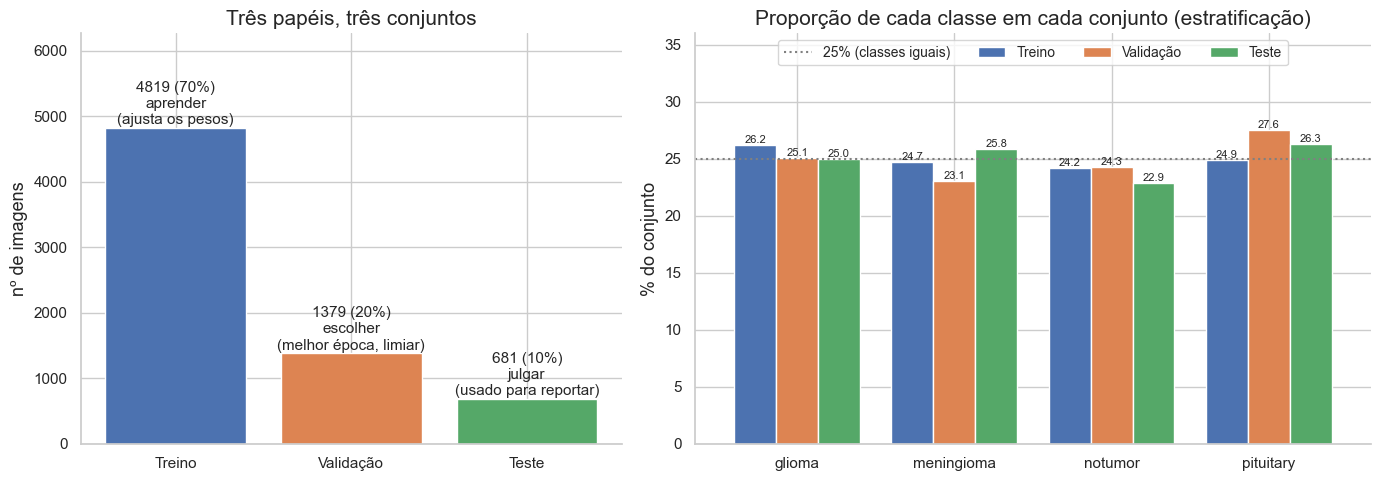

salvo: 01_papeis_estratificacao.png


In [6]:
cnt = pd.DataFrame({NOME_S[s]: np.bincount(Y[s], minlength=NC) for s in SPL3}, index=CLASSES); prop = cnt / cnt.sum()
chi2, p_chi, dof, _ = chi2_contingency(cnt.values); maxdev = float((prop.sub(prop.mean(axis=1), axis=0)).abs().values.max() * 100)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
tot = cnt.sum(); papeis = {"Treino": "aprender\n(ajusta os pesos)", "Validação": "escolher\n(melhor época, limiar)", "Teste": "julgar\n(usado para reportar)"}
bars = ax[0].bar(tot.index, tot.values, color=["#4c72b0", "#dd8452", "#55a868"])
for b_, n_, nm in zip(bars, tot.values, tot.index): ax[0].text(b_.get_x() + b_.get_width() / 2, n_ + 60, f"{n_} ({100*n_/tot.sum():.0f}%)\n{papeis[nm]}", ha="center", fontsize=11)
ax[0].set_ylim(0, tot.max() * 1.3); ax[0].set_ylabel("nº de imagens"); ax[0].set_title("Três papéis, três conjuntos")
(prop * 100).plot.bar(ax=ax[1], rot=0, color=["#4c72b0", "#dd8452", "#55a868"], width=.8); ax[1].axhline(100 / NC, color="gray", ls=":", label=f"{100/NC:.0f}% (classes iguais)")
ax[1].set_ylabel("% do conjunto"); ax[1].set_title("Proporção de cada classe em cada conjunto (estratificação)"); ax[1].legend(fontsize=10, loc="upper center", ncol=4); ax[1].set_ylim(0, 36)
for c_ in ax[1].containers: ax[1].bar_label(c_, fmt="%.1f", fontsize=8)
plt.tight_layout(); NUM.update(chi2_p_estratificacao=round(float(p_chi), 3), maior_desvio_proporcao_pp=round(maxdev, 2), razao_maior_menor_classe_treino=round(cnt["Treino"].max() / cnt["Treino"].min(), 2))
frase = "sem evidência de que as proporções difiram entre os conjuntos" if p_chi > .05 else "há diferença estatística nas proporções, embora pequena em pontos percentuais"
salvar("01_papeis_estratificacao.png", "Papéis dos conjuntos e conferência da estratificação",
       "À esquerda, o tamanho e o papel de cada conjunto (Aula 01: treino aprende, validação escolhe, teste julga). À direita, a proporção de cada classe dentro de cada conjunto; a linha pontilhada é o que se teria com classes perfeitamente iguais.",
       "Barras de uma mesma classe com alturas parecidas nos três conjuntos indicam divisão estratificada (Aula 05: 'confira que as proporções bateram'). As classes próximas de 25% indicam conjunto balanceado, caso em que a acurácia não é enganosa como no exemplo do dummy (Aula 02).",
       f"Divisão {100*tot['Treino']/tot.sum():.0f}/{100*tot['Validação']/tot.sum():.0f}/{100*tot['Teste']/tot.sum():.0f}. A maior diferença de proporção entre conjuntos é {maxdev:.1f} p.p. (teste χ²: p = {p_chi:.2f}; {frase}). Razão entre a maior e a menor classe no treino: {NUM['razao_maior_menor_classe_treino']:.2f}.")

## Figura 2 — Curva por época: gap, platô, faixa de empate e otimismo da escolha (Aulas 01, 10 e 09)
O "hiperparâmetro" que varia ao longo do treino é o **número de épocas**. A curva de validação por época segue a leitura da Aula 10: três regiões (subajuste → ótimo → sobreajuste), **faixa de empate** (melhor − 1 desvio) e **platô**. A Aula 09 alerta que o melhor valor da validação é **otimista** ("quem escolhe não mede"): comparamos com o teste, que não participou da escolha.

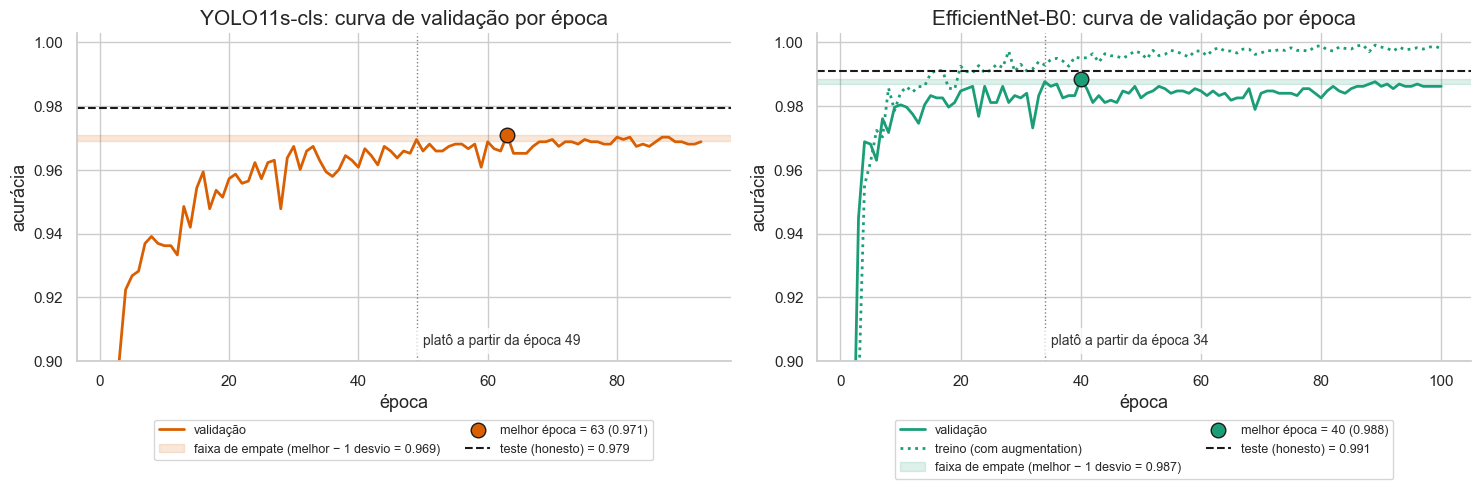

salvo: 02_curva_por_epoca.png


In [7]:
def curva(m):
    if m == NOME_Y: ep, va, tr = hist_y["epoch"].values, hist_y["metrics/accuracy_top1"].values, None
    else: ep, va, tr = hist_c["epoca"].values, hist_c["acc_val"].values, hist_c["acc_treino"].values
    late = va[len(va) // 2:]; sd = late.std(ddof=1); b = int(va.argmax()); best = va[b]; faixa = best - sd; dentro = ep[va >= faixa]
    return dict(ep=ep, va=va, tr=tr, sd=sd, best=best, ep_best=int(ep[b]), faixa=faixa, plato_ini=int(dentro.min()), n_dentro=int((va >= faixa).sum()), media_tardia=late.mean(), otimismo=best - late.mean())
CV = {m: curva(m) for m in MODELOS}; fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for a, m in zip(ax, MODELOS):
    c = CV[m]; a.plot(c["ep"], c["va"], color=COR[m], lw=2, label="validação")
    if c["tr"] is not None: a.plot(c["ep"], c["tr"], color=COR[m], ls=":", lw=2, label="treino (com augmentation)")
    a.axhspan(c["faixa"], c["best"], color=COR[m], alpha=.15, label=f"faixa de empate (melhor − 1 desvio = {c['faixa']:.3f})")
    a.scatter([c["ep_best"]], [c["best"]], s=110, color=COR[m], edgecolor="k", zorder=5, label=f"melhor época = {c['ep_best']} ({c['best']:.3f})")
    a.axhline(acc(m, "test"), color="k", ls="--", lw=1.5, label=f"teste (honesto) = {acc(m, 'test'):.3f}")
    a.axvline(c["plato_ini"], color="gray", ls=":", lw=1); a.text(c["plato_ini"] + 1, .905, f"platô a partir da época {c['plato_ini']}", fontsize=10, color="#333", bbox=dict(fc="white", ec="none", alpha=.8))
    a.set_ylim(.9, 1.003); a.set_xlabel("época"); a.set_ylabel("acurácia"); a.set_title(f"{m}: curva de validação por época"); a.legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2, fontsize=9)
plt.tight_layout()
for m in MODELOS:
    c = CV[m]; NUM[f"melhor_epoca_{m}"] = c["ep_best"]; NUM[f"plato_inicio_{m}"] = c["plato_ini"]; NUM[f"otimismo_selecao_pp_{m}"] = round(100 * c["otimismo"], 2); NUM[f"desvio_val_tardio_{m}"] = round(c["sd"], 4); NUM[f"epocas_{m}"] = int(len(c["ep"]))
salvar("02_curva_por_epoca.png", "Curva de validação por época: platô, faixa de empate e otimismo da seleção",
       "Acurácia de validação a cada época (e de treino, no caso da CNN, que registrou essa métrica), a faixa de empate (melhor − 1 desvio da fase final), a melhor época escolhida e, como linha tracejada, a acurácia no teste, que não participou da escolha.",
       "Aula 10: o pico não decide sozinho; dentro da faixa de empate vale o ponto mais cedo/simples (menor gap e menos risco de sorte). A distância entre o melhor valor da validação e a média da fase final mede o otimismo da escolha (Aula 09: 'o best_score_ é otimista'); o teste é a referência honesta.",
       f"YOLO: melhor época {CV[NOME_Y]['ep_best']} (validação {CV[NOME_Y]['best']:.3f}); a curva entra na faixa de empate na época {CV[NOME_Y]['plato_ini']} e fica em platô; otimismo da seleção ≈ {100*CV[NOME_Y]['otimismo']:.2f} p.p.; teste {acc(NOME_Y,'test'):.3f}. "
       f"CNN: melhor época {CV[NOME_C]['ep_best']} (validação {CV[NOME_C]['best']:.3f}); platô a partir da época {CV[NOME_C]['plato_ini']}; otimismo ≈ {100*CV[NOME_C]['otimismo']:.2f} p.p.; teste {acc(NOME_C,'test'):.3f}. O teste ficou próximo ou acima do melhor valor da validação, sem sinal de seleção inflando o resultado, e treino e validação sem divergência crescente (sem sobreajuste acentuado).")

## Figura 3 — Contra o classificador burro e contra a prevalência (Aulas 02 e 03)
A Aula 02 ensina a comparar com o **dummy** (sempre a classe mais comum) e a Aula 03, a usar a **prevalência como base do log-loss**. Aqui também entra o **modelo de atalhos**: um classificador que só vê atributos triviais da imagem. Os modelos treinados precisam bater esses pisos com folga.

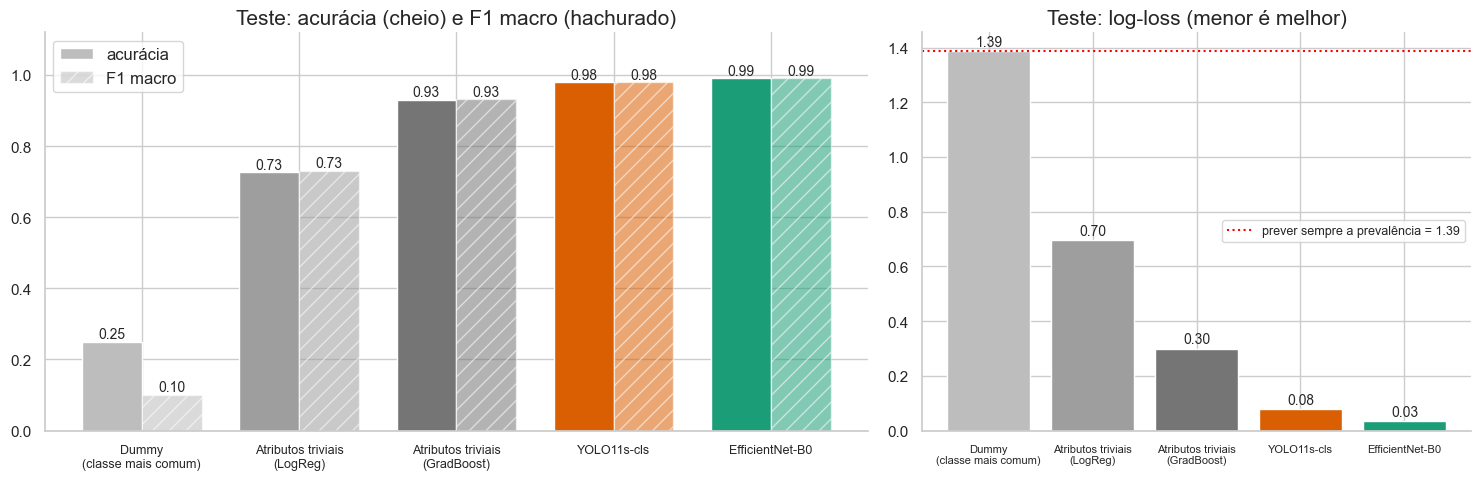

salvo: 03_comparacao_com_baselines.png


In [8]:
ytr = Y["train"]; dummy = DummyClassifier(strategy="prior").fit(FT["train"], ytr); pd_ = {s: dummy.predict_proba(FT[s]) for s in ("val", "test")}
lr_ = Pipeline([("pad", StandardScaler()), ("clf", LogisticRegression(max_iter=4000))]).fit(FT["train"], ytr)
hgb = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(FT["train"], ytr)
base = {"Dummy (classe mais comum)": dummy, "Só atributos triviais (LogReg)": lr_, "Só atributos triviais (GradBoost)": hgb}
BS = {}
for nome, mdl in base.items():
    P = mdl.predict_proba(FT["test"]); BS[nome] = dict(acc=accuracy_score(Y["test"], P.argmax(1)), f1=f1_score(Y["test"], P.argmax(1), average="macro"), ll=log_loss(Y["test"], P, labels=list(range(NC))))
for m in MODELOS: BS[m] = dict(acc=acc(m, "test"), f1=f1_score(Y["test"], PRED[m]["test"], average="macro"), ll=log_loss(Y["test"], PROB[m]["test"], labels=list(range(NC))))
prev = np.bincount(ytr) / len(ytr); ll_prev = log_loss(Y["test"], np.tile(prev, (len(Y["test"]), 1)), labels=list(range(NC)))
nomes = list(BS); cores = ["#bdbdbd", "#9e9e9e", "#757575", COR[NOME_Y], COR[NOME_C]]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]}); x = np.arange(len(nomes)); w = .38
ax[0].bar(x - w / 2, [BS[n]["acc"] for n in nomes], w, color=cores, label="acurácia"); ax[0].bar(x + w / 2, [BS[n]["f1"] for n in nomes], w, color=cores, alpha=.55, hatch="//", label="F1 macro")
for xi, n in zip(x, nomes): ax[0].text(xi - w / 2, BS[n]["acc"] + .01, f"{BS[n]['acc']:.2f}", ha="center", fontsize=10); ax[0].text(xi + w / 2, BS[n]["f1"] + .01, f"{BS[n]['f1']:.2f}", ha="center", fontsize=10)
ROT = ["Dummy\n(classe mais comum)", "Atributos triviais\n(LogReg)", "Atributos triviais\n(GradBoost)", "YOLO11s-cls", "EfficientNet-B0"]
ax[0].set_xticks(x); ax[0].set_xticklabels(ROT, fontsize=9); ax[0].set_ylim(0, 1.12); ax[0].set_title("Teste: acurácia (cheio) e F1 macro (hachurado)"); ax[0].legend(loc="upper left")
ax[1].bar(x, [BS[n]["ll"] for n in nomes], color=cores); ax[1].axhline(ll_prev, color="red", ls=":", label=f"prever sempre a prevalência = {ll_prev:.2f}")
for xi, n in zip(x, nomes): ax[1].text(xi, BS[n]["ll"] + .02, f"{BS[n]['ll']:.2f}", ha="center", fontsize=10)
ax[1].set_xticks(x); ax[1].set_xticklabels(ROT, fontsize=8)
ax[1].set_title("Teste: log-loss (menor é melhor)"); ax[1].legend(fontsize=9); plt.tight_layout()
NUM.update(acc_dummy_teste=round(BS["Dummy (classe mais comum)"]["acc"], 4), f1_dummy_teste=round(BS["Dummy (classe mais comum)"]["f1"], 4), logloss_prevalencia=round(ll_prev, 4),
           acc_atalhos_logreg_teste=round(BS["Só atributos triviais (LogReg)"]["acc"], 4), acc_atalhos_gradboost_teste=round(BS["Só atributos triviais (GradBoost)"]["acc"], 4), logloss_atalhos_gradboost_teste=round(BS["Só atributos triviais (GradBoost)"]["ll"], 4))
for m in MODELOS: NUM[f"f1_macro_teste_{m}"] = round(BS[m]["f1"], 4); NUM[f"logloss_teste_{m}"] = round(BS[m]["ll"], 4); NUM[f"acc_teste_{m}"] = round(BS[m]["acc"], 4)
salvar("03_comparacao_com_baselines.png", "Os modelos contra o classificador burro, a prevalência e um modelo de atalhos",
       "Acurácia e F1 macro no teste, e log-loss no teste, para quatro referências simples (dummy que chuta a classe mais comum, prevalência das classes, e dois modelos que só enxergam atributos triviais da imagem) contra o YOLO e a CNN.",
       "Aula 02: a acurácia só impressiona se superar o dummy; o F1 macro revela o que a acurácia dilui. Aula 03: o log-loss tem de ficar bem abaixo da base da prevalência. Se um modelo de atalhos chegasse perto dos modelos treinados, desconfiaríamos de vazamento (Aula 14).",
       f"Dummy: acurácia {BS['Dummy (classe mais comum)']['acc']:.2f} e F1 {BS['Dummy (classe mais comum)']['f1']:.2f} (com 4 classes quase iguais, o piso é ~25%, e não 85% como no exemplo da aula). Log-loss da prevalência: {ll_prev:.2f}. Atributos triviais (GradBoost): acurácia {BS['Só atributos triviais (GradBoost)']['acc']:.2f}. YOLO: {BS[NOME_Y]['acc']:.3f} / log-loss {BS[NOME_Y]['ll']:.3f}; CNN: {BS[NOME_C]['acc']:.3f} / {BS[NOME_C]['ll']:.3f}.")

## Figura 4 — Auditoria de atalhos (Aula 14: "target leakage" nas imagens)
A Aula 14 manda **auditar as colunas**: uma que sozinha prevê o alvo denuncia vazamento. Em imagens, o análogo são **artefatos de aquisição** (brilho, tamanho do crânio, bordas) que dependem da origem da imagem e não da doença. Se atributos triviais preverem bem a classe, parte do desempenho dos modelos pode vir de atalhos.

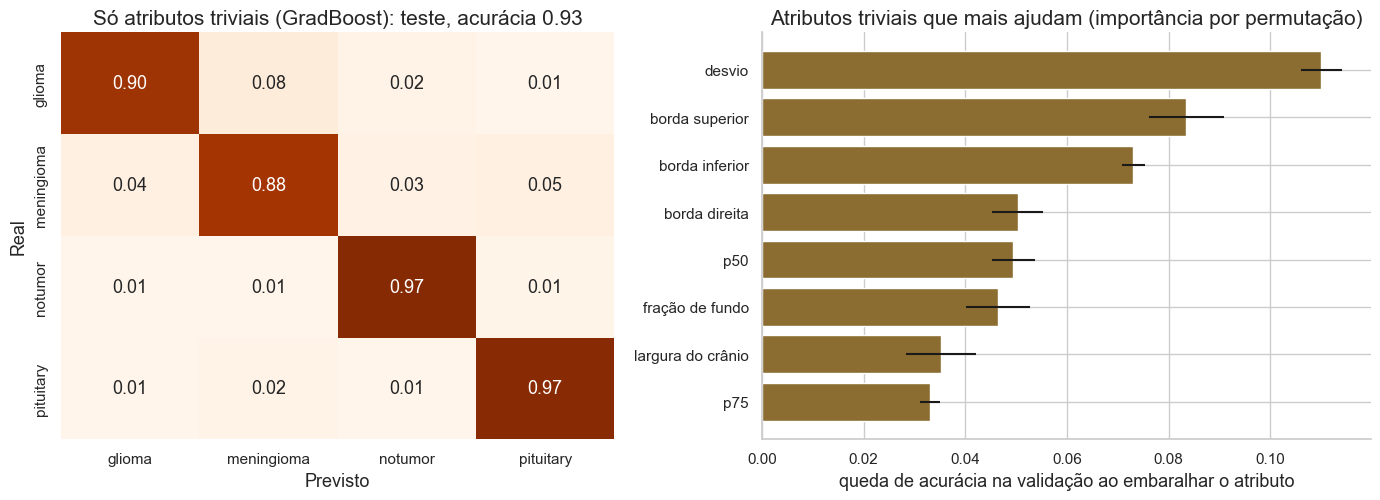

salvo: 04_auditoria_de_atalhos.png


In [9]:
Ph = hgb.predict(FT["test"]); cmn = confusion_matrix(Y["test"], Ph, normalize="true"); acc_h = accuracy_score(Y["test"], Ph); acc_hv = accuracy_score(Y["val"], hgb.predict(FT["val"]))
pi = permutation_importance(hgb, FT["val"], Y["val"], n_repeats=5, random_state=SEED, scoring="accuracy"); ordem = np.argsort(-pi.importances_mean)[:8]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False); ax[0].set_title(f"Só atributos triviais (GradBoost): teste, acurácia {acc_h:.2f}"); ax[0].set_xlabel("Previsto"); ax[0].set_ylabel("Real")
ax[1].barh([FEATN[i] for i in ordem][::-1], pi.importances_mean[ordem][::-1], xerr=pi.importances_std[ordem][::-1], color="#8c6d31"); ax[1].set_xlabel("queda de acurácia na validação ao embaralhar o atributo"); ax[1].set_title("Atributos triviais que mais ajudam (importância por permutação)")
plt.tight_layout(); top3 = [FEATN[i] for i in ordem[:3]]; fator = acc_h / (1 / NC); acc_hl = accuracy_score(Y["test"][LIMPO_T], Ph[LIMPO_T])
NUM.update(acc_atalhos_gradboost_val=round(acc_hv, 4), acc_atalhos_gradboost_teste_limpo=round(acc_hl, 4), atalhos_top1=top3[0], atalhos_top2=top3[1], atalhos_top3=top3[2])
nivel = "alerta: há sinais fortes de atalhos de aquisição" if acc_h > .6 else ("atenção: os atributos triviais já preveem bem acima do acaso" if acc_h > .4 else "sem sinal relevante de atalhos")
salvar("04_auditoria_de_atalhos.png", "Auditoria de atalhos: o que atributos triviais da imagem conseguem prever",
       "Matriz de confusão (teste) de um classificador que só enxerga 18 atributos triviais da imagem (brilho, contraste, fração de fundo preto, tamanho do crânio, bordas, cantos) e os atributos mais importantes para ele (importância por permutação na validação).",
       "Se atributos que nada dizem sobre tumor preveem bem a classe, a origem/aquisição das imagens está correlacionada com o rótulo e os modelos profundos podem estar usando esse atalho (Aula 14: 'bom demais', 'correlação quase perfeita'). Acurácia perto de 25% (acaso) indica ausência de atalho simples.",
       f"Acurácia do modelo de atalhos: {acc_h:.2f} no teste ({acc_hl:.2f} no teste limpo; {acc_hv:.2f} na validação), contra {1/NC:.2f} do acaso (≈{fator:.1f}×) e {acc(NOME_C,'test'):.2f}/{acc(NOME_Y,'test'):.2f} dos modelos profundos. Atributos mais úteis: {', '.join(top3)}. Leitura: {nivel}. Isso não prova que os modelos profundos usem esses atalhos, mas mostra que cerca de {100*acc_h:.0f}% da tarefa pode ser resolvida sem olhar a lesão: o ganho dos modelos profundos sobre esse atalho é de apenas ≈{100*(acc(NOME_C,'test')-acc_h):.0f} p.p. (CNN) e ≈{100*(acc(NOME_Y,'test')-acc_h):.0f} p.p. (YOLO). A acurácia de 98–99% deve ser lida com essa ressalva; validar em imagens de outra origem é o próximo passo.")

## Figura 5 — O relatório de classificação e o F-beta para tumor (Aula 02)
A Aula 02 termina no `classification_report`: precisão, recall, F1 e suporte por classe, com **macro** (cada classe pesa igual) e **ponderada** (pesa pelo suporte). Na visão tumor × sem tumor, o falso negativo é o erro caro, então o **F2** (valoriza o recall) e a **especificidade** acompanham.

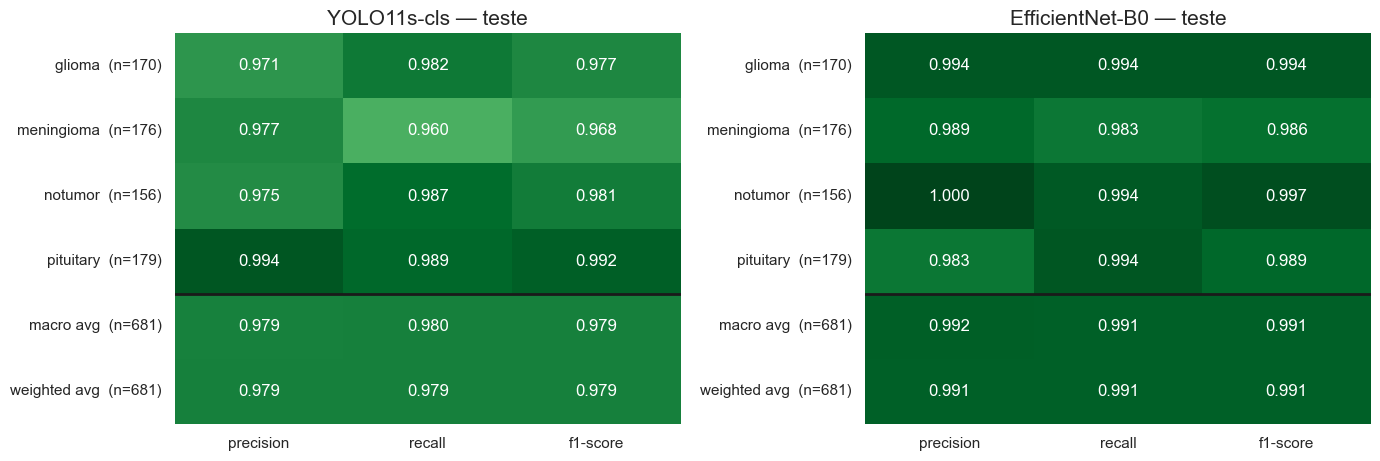

salvo: 05_relatorio_de_classificacao.png


In [10]:
def rel(m):
    r = classification_report(Y["test"], PRED[m]["test"], target_names=CLASSES, output_dict=True, digits=4)
    t = pd.DataFrame({k: r[k] for k in CLASSES + ["macro avg", "weighted avg"]}).T[["precision", "recall", "f1-score", "support"]]; return t
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); RELT = {}
for a, m in zip(ax, MODELOS):
    t = rel(m); RELT[m] = t; lab = t.copy(); lab_str = lab.copy().astype(object)
    for c in ("precision", "recall", "f1-score"): lab_str[c] = lab[c].map(lambda v: f"{v:.3f}")
    lab_str["support"] = lab["support"].astype(int).astype(str)
    sns.heatmap(t[["precision", "recall", "f1-score"]], annot=lab_str[["precision", "recall", "f1-score"]].values, fmt="", cmap="Greens", vmin=.9, vmax=1, ax=a, cbar=False, annot_kws={"size": 12})
    a.set_yticklabels([f"{n}  (n={int(s_)})" for n, s_ in zip(t.index, t["support"])], rotation=0); a.set_title(f"{m} — teste"); a.axhline(NC, color="k", lw=2)
plt.tight_layout()
yt, spe = (Y["test"] != i_nt), {}
for m in MODELOS:
    pt = PRED[m]["test"] != i_nt; tn, fp_ = int((~yt & ~pt).sum()), int((~yt & pt).sum()); spe[m] = dict(f2=fbeta_score(yt, pt, beta=2), esp=tn / (tn + fp_), rec=recall_score(yt, pt), pre=precision_score(yt, pt), f1=f1_score(yt, pt))
    NUM[f"f2_tumor_{m}"] = round(spe[m]["f2"], 4); NUM[f"especificidade_{m}"] = round(spe[m]["esp"], 4); NUM[f"sensibilidade_tumor_{m}"] = round(spe[m]["rec"], 4); NUM[f"recall_macro_teste_{m}"] = round(RELT[m].loc["macro avg", "recall"], 4)
    NUM[f"menor_recall_classe_{m}"] = round(RELT[m].loc[CLASSES, "recall"].min(), 4); NUM[f"classe_menor_recall_{m}"] = RELT[m].loc[CLASSES, "recall"].idxmin()
salvar("05_relatorio_de_classificacao.png", "Relatório de classificação por classe (precisão, recall e F1)",
       "O equivalente ao classification_report da Aula 02 para cada modelo no teste: precisão, recall e F1 de cada classe, a média macro (cada classe pesa igual) e a ponderada pelo suporte. Abaixo da linha escura, as médias.",
       "A linha de cada classe mostra onde o modelo é mais fraco; a média macro dá voz à classe mais difícil e a ponderada se aproxima da acurácia. Verde mais escuro = melhor.",
       f"Pior recall por classe: YOLO {NUM['menor_recall_classe_'+NOME_Y]:.3f} ({NUM['classe_menor_recall_'+NOME_Y]}), CNN {NUM['menor_recall_classe_'+NOME_C]:.3f} ({NUM['classe_menor_recall_'+NOME_C]}). Na visão tumor × sem tumor: F2 de {spe[NOME_Y]['f2']:.3f} (YOLO) e {spe[NOME_C]['f2']:.3f} (CNN); especificidade {spe[NOME_Y]['esp']:.3f} e {spe[NOME_C]['esp']:.3f}; sensibilidade {spe[NOME_Y]['rec']:.3f} e {spe[NOME_C]['rec']:.3f}.")

## Figura 6 — ROC e Precisão-Recall: "o modelo ordena bem?" (Aula 03)
A Aula 03 separa duas perguntas: **a nota ordena bem os casos?** (ROC/AUC e PR/AP, independentes de corte) e **no corte, a decisão acerta?** (precisão, recall, F1). Aqui está a primeira. A PR é a visão "honesta" quando a classe de interesse é rara; nosso conjunto é balanceado, então as duas devem concordar.

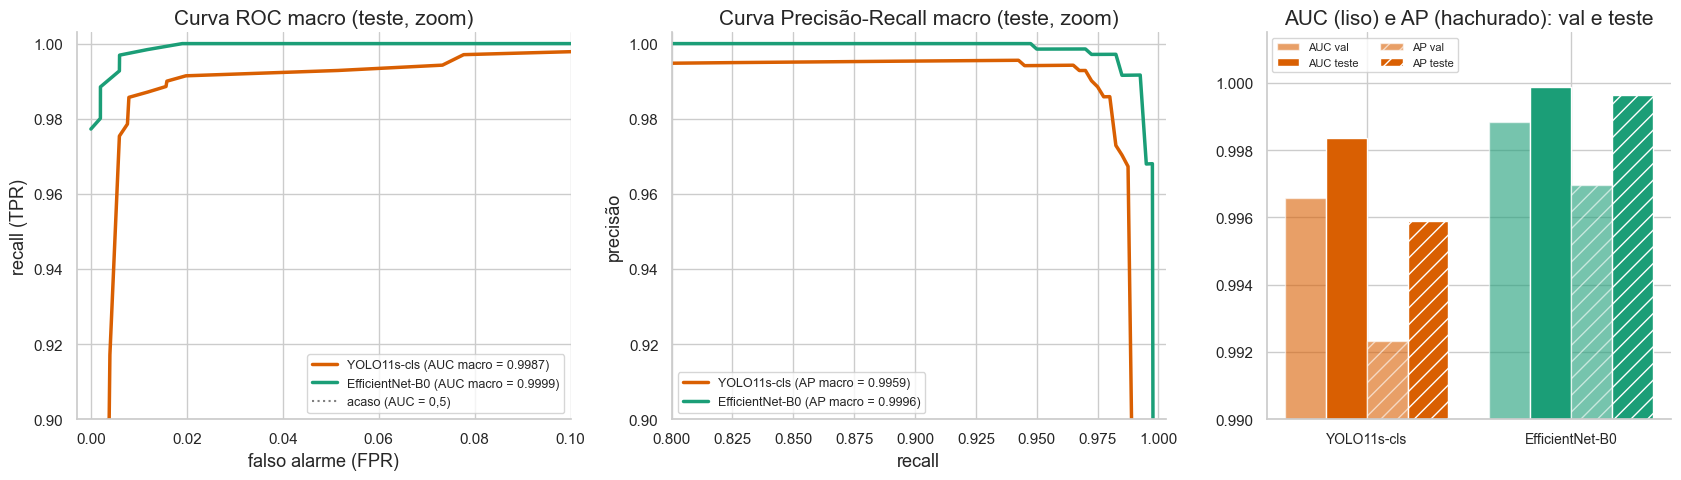

salvo: 06_roc_e_precisao_recall.png


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.1, 1.1, .9]}); AUCM, APM = {}, {}; grade = np.linspace(0, 1, 401)
for m in MODELOS:
    f, t, a_ = roc_macro(Y["test"], PROB[m]["test"]); AUCM[m] = a_; ax[0].plot(f, t, color=COR[m], lw=2.5, label=f"{m} (AUC macro = {a_:.4f})")
    Yb = np.eye(NC)[Y["test"]]; curvas = []
    for i in range(NC):
        pr_, rc_, _ = precision_recall_curve(Yb[:, i], PROB[m]["test"][:, i]); curvas.append(np.interp(grade, rc_[::-1], pr_[::-1]))
    APM[m] = average_precision_score(Yb, PROB[m]["test"], average="macro"); ax[1].plot(grade, np.mean(curvas, 0), color=COR[m], lw=2.5, label=f"{m} (AP macro = {APM[m]:.4f})")
ax[0].plot([0, 1], [0, 1], ":", color="gray", label="acaso (AUC = 0,5)"); ax[0].set_xlim(-.003, .1); ax[0].set_ylim(.9, 1.003); ax[0].set_xlabel("falso alarme (FPR)"); ax[0].set_ylabel("recall (TPR)"); ax[0].set_title("Curva ROC macro (teste, zoom)"); ax[0].legend(loc="lower right", fontsize=9)
ax[1].set_xlim(.8, 1.003); ax[1].set_ylim(.9, 1.003); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisão"); ax[1].set_title("Curva Precisão-Recall macro (teste, zoom)"); ax[1].legend(loc="lower left", fontsize=9)
AUCs = pd.DataFrame({m: {s: roc_auc_score(Y[s], PROB[m][s], multi_class="ovr") for s in ("val", "test")} for m in MODELOS}).T; APs = pd.DataFrame({m: {s: average_precision_score(np.eye(NC)[Y[s]], PROB[m][s], average="macro") for s in ("val", "test")} for m in MODELOS}).T
xx = np.arange(2); w = .2
for j, (nm, d_, h) in enumerate((("AUC val", AUCs["val"], ""), ("AUC teste", AUCs["test"], ""), ("AP val", APs["val"], "//"), ("AP teste", APs["test"], "//"))):
    ax[2].bar(xx + (j - 1.5) * w, d_.values, w, color=[COR[m] for m in MODELOS], alpha=1 if "teste" in nm else .6, hatch=h, label=nm)
ax[2].set_xticks(xx); ax[2].set_xticklabels(MODELOS, fontsize=10); ax[2].set_ylim(.99, 1.0015); ax[2].set_title("AUC (liso) e AP (hachurado): val e teste"); ax[2].legend(fontsize=8, ncol=2, loc="upper left"); plt.tight_layout()
for m in MODELOS: NUM[f"auc_macro_teste_{m}"] = round(AUCM[m], 4); NUM[f"ap_macro_teste_{m}"] = round(APM[m], 4)
salvar("06_roc_e_precisao_recall.png", "ROC e Precisão-Recall: qualidade da ordenação, sem depender de corte",
       "Curva ROC macro e curva Precisão-Recall macro (média das 4 classes um-contra-todos) no teste, em zoom no canto de interesse, e a AUC e a AP macro em validação e teste.",
       "ROC: quanto mais colada ao canto superior esquerdo, melhor; AUC 0,5 = acaso, 1,0 = ordenação perfeita (Aula 03). PR: quanto mais ao canto superior direito, melhor. Como as classes são equilibradas, ROC e PR contam a mesma história (a PR só diverge da ROC quando o 'sim' é raro).",
       f"AUC macro no teste: YOLO {AUCM[NOME_Y]:.4f} e CNN {AUCM[NOME_C]:.4f}; AP macro: {APM[NOME_Y]:.4f} e {APM[NOME_C]:.4f}. Ordenar bem não é o mesmo que decidir bem no corte nem ter probabilidade honesta: são perguntas separadas (figuras 7, 9 e 10).")

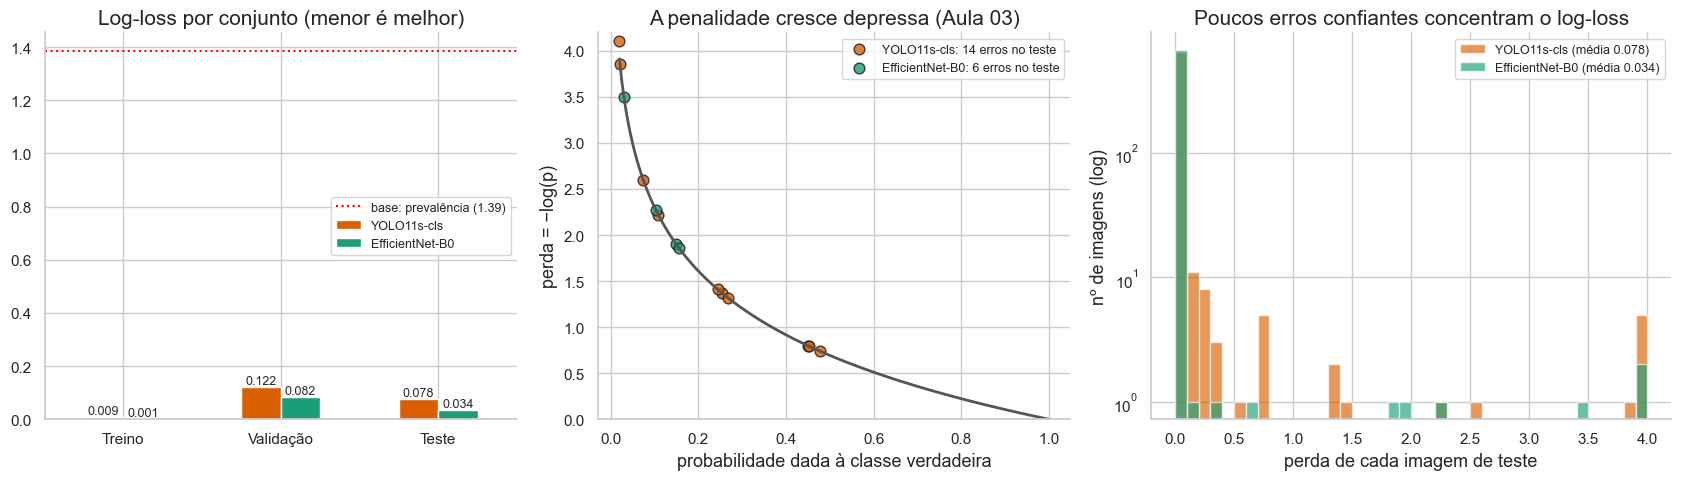

salvo: 07_log_loss.png


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.1]}); LLd = pd.DataFrame({NOME_S[s]: {m: log_loss(Y[s], PROB[m][s], labels=list(range(NC))) for m in MODELOS} for s in SPL3})
LLd.T.plot.bar(ax=ax[0], rot=0, color=[COR[m] for m in MODELOS]); ax[0].axhline(ll_prev, color="red", ls=":", label=f"base: prevalência ({ll_prev:.2f})"); ax[0].set_title("Log-loss por conjunto (menor é melhor)"); ax[0].legend(fontsize=9)
for c_ in ax[0].containers: ax[0].bar_label(c_, fmt="%.3f", fontsize=9)
pgrid = np.linspace(.02, 1, 200); ax[1].plot(pgrid, -np.log(pgrid), color="#555", lw=2); ax[1].set_xlabel("probabilidade dada à classe verdadeira"); ax[1].set_ylabel("perda = −log(p)"); ax[1].set_title("A penalidade cresce depressa (Aula 03)")
for m in MODELOS:
    pt = PROB[m]["test"][np.arange(len(Y["test"])), Y["test"]]; err = pt[PRED[m]["test"] != Y["test"]]; ax[1].scatter(np.clip(err, .02, 1), -np.log(np.clip(err, 1e-12, 1)), color=COR[m], s=60, alpha=.8, edgecolor="k", label=f"{m}: {len(err)} erros no teste")
ax[1].set_ylim(0, 4.2); ax[1].legend(fontsize=9, loc="upper right")
for m in MODELOS:
    l = -np.log(np.clip(PROB[m]["test"][np.arange(len(Y["test"])), Y["test"]], 1e-12, 1)); ax[2].hist(np.clip(l, 0, 4), bins=np.linspace(0, 4, 41), alpha=.65, color=COR[m], label=f"{m} (média {l.mean():.3f})")
ax[2].set_yscale("log"); ax[2].set_xlabel("perda de cada imagem de teste"); ax[2].set_ylabel("nº de imagens (log)"); ax[2].set_title("Poucos erros confiantes concentram o log-loss"); ax[2].legend(fontsize=9); plt.tight_layout()
conc = {}
for m in MODELOS:
    l = -np.log(np.clip(PROB[m]["test"][np.arange(len(Y["test"])), Y["test"]], 1e-12, 1)); k = max(1, int(.05 * len(l))); conc[m] = 100 * np.sort(l)[::-1][:k].sum() / l.sum(); NUM[f"concentracao_logloss_top5pct_{m}"] = round(conc[m], 1)
    for s in SPL3: NUM[f"logloss_{NOME_S[s]}_{m}"] = round(LLd.loc[m, NOME_S[s]], 4)
salvar("07_log_loss.png", "Log-loss: a probabilidade é confiável, não só o acerto?",
       "Log-loss de cada modelo em treino, validação e teste contra a base de comparação (sempre prever a prevalência das classes); a curva −log(p) com os erros reais do teste sobre ela; e a distribuição da perda por imagem.",
       "Menor é melhor, e o valor precisa ficar muito abaixo da base. Errar com certeza (probabilidade baixa na classe certa) custa muito mais do que errar com dúvida: os pontos mais altos da curva são os erros confiantes (Aula 03).",
       f"Log-loss no teste: YOLO {LLd.loc[NOME_Y,'Teste']:.3f} e CNN {LLd.loc[NOME_C,'Teste']:.3f}, contra {ll_prev:.2f} da base da prevalência. Os 5% de imagens de maior perda respondem por {conc[NOME_Y]:.0f}% (YOLO) e {conc[NOME_C]:.0f}% (CNN) do log-loss total: poucos erros confiantes dominam o valor.")

## Figura 8 — Estabilidade por dobras e faixa de empate (Aulas 06, 07 e 12)
A Aula 06 mostra que **um corte só é jogar a moeda** e que o resultado honesto é **média ± desvio**; a Aula 12 define comparação justa como **pareada, nas mesmas dobras**, com **faixa de empate** (melhor − 1 desvio): dentro dela, fica o mais simples/rápido. Treinar de novo em k dobras custaria dezenas de horas, então aplicamos a ideia à **avaliação**: o teste é dividido em 5 dobras estratificadas, repetido 10 vezes (`RepeatedStratifiedKFold`), e cada dobra pontua os dois modelos nas mesmas imagens. Isso mede a oscilação da *amostra de teste*, não a do *treino*.

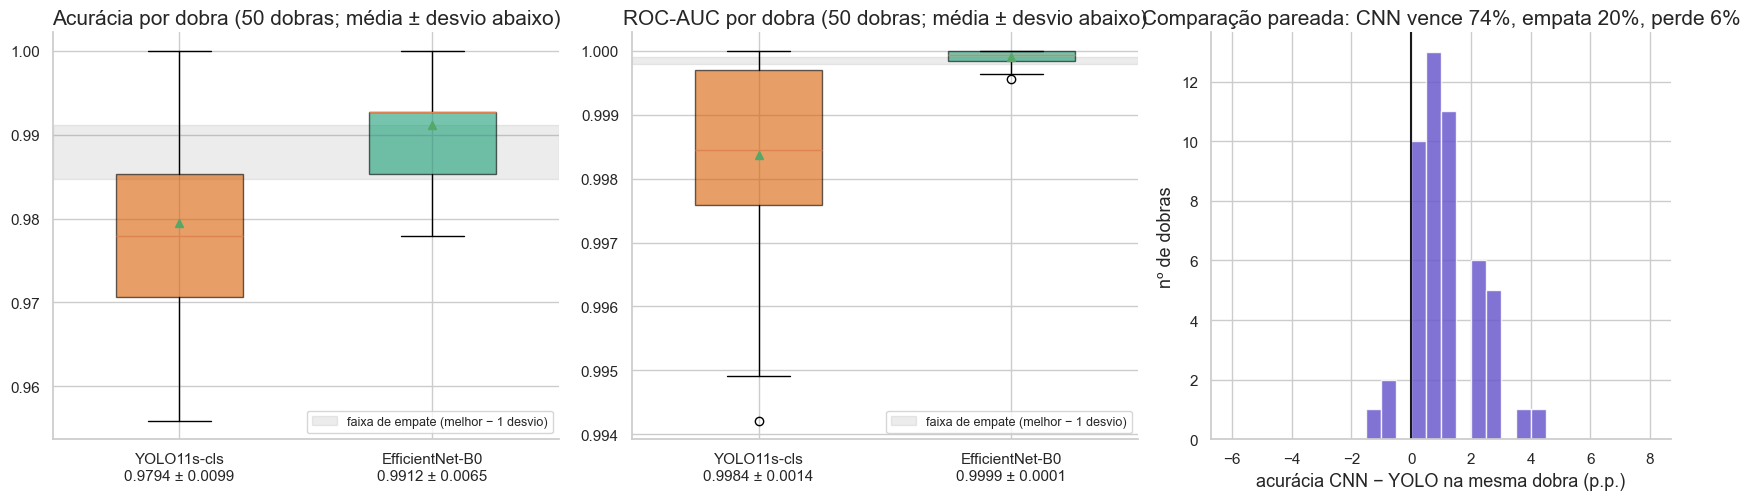

salvo: 08_estabilidade_por_dobras.png


In [13]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED); FOLD = {m: {"acc": [], "f1": [], "auc": []} for m in MODELOS}; nfold = []
for _, idx in rskf.split(np.zeros(len(Y["test"])), Y["test"]):
    nfold.append(len(idx))
    for m in MODELOS:
        yy, P = Y["test"][idx], PROB[m]["test"][idx]; pr = P.argmax(1); FOLD[m]["acc"].append((pr == yy).mean()); FOLD[m]["f1"].append(f1_score(yy, pr, average="macro")); FOLD[m]["auc"].append(roc_auc_score(yy, P, multi_class="ovr"))
FOLD = {m: {k: np.array(v) for k, v in d.items()} for m, d in FOLD.items()}; dif = FOLD[NOME_C]["acc"] - FOLD[NOME_Y]["acc"]
vit, emp, der = float((dif > 0).mean()), float((dif == 0).mean()), float((dif < 0).mean())
mu = {m: FOLD[m]["acc"].mean() for m in MODELOS}; sd = {m: FOLD[m]["acc"].std(ddof=1) for m in MODELOS}; lider = max(mu, key=mu.get); outro = [m for m in MODELOS if m != lider][0]; faixa = mu[lider] - sd[lider]; empate = mu[outro] >= faixa
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
for a, k, tit in ((ax[0], "acc", "Acurácia por dobra"), (ax[1], "auc", "ROC-AUC por dobra")):
    bp = a.boxplot([FOLD[m][k] for m in MODELOS], labels=[f"{m}\n{FOLD[m][k].mean():.4f} ± {FOLD[m][k].std(ddof=1):.4f}" for m in MODELOS], patch_artist=True, widths=.5, showmeans=True)
    for p_, m in zip(bp["boxes"], MODELOS): p_.set_facecolor(COR[m]); p_.set_alpha(.6)
    ml = max(MODELOS, key=lambda m: FOLD[m][k].mean()); fx = FOLD[ml][k].mean() - FOLD[ml][k].std(ddof=1); a.axhspan(fx, FOLD[ml][k].mean(), color="gray", alpha=.15, label="faixa de empate (melhor − 1 desvio)")
    a.set_title(f"{tit} (50 dobras; média ± desvio abaixo)"); a.legend(fontsize=9, loc="lower right")
ax[2].hist(100 * dif, bins=np.linspace(-6, 8, 29), color="#6a5acd", alpha=.85); ax[2].axvline(0, color="k", lw=1.5); ax[2].set_xlabel("acurácia CNN − YOLO na mesma dobra (p.p.)"); ax[2].set_ylabel("nº de dobras")
ax[2].set_title(f"Comparação pareada: CNN vence {100*vit:.0f}%, empata {100*emp:.0f}%, perde {100*der:.0f}%"); plt.tight_layout()
for m in MODELOS: NUM[f"dobras_acc_media_{m}"] = round(mu[m], 4); NUM[f"dobras_acc_desvio_{m}"] = round(sd[m], 4); NUM[f"dobras_auc_media_{m}"] = round(FOLD[m]["auc"].mean(), 4); NUM[f"dobras_auc_desvio_{m}"] = round(FOLD[m]["auc"].std(ddof=1), 4)
NUM.update(dobras_cnn_vence_pct=round(100 * vit, 1), dobras_empate_pct=round(100 * emp, 1), dobras_yolo_vence_pct=round(100 * der, 1), tamanho_dobra_teste=int(np.median(nfold)), dobras_total=len(nfold), dobras_empate_tecnico=int(empate))
sent = f"{outro} está dentro da faixa de empate de {lider} (média − 1 desvio = {faixa:.4f}); em empate técnico vale o modelo mais simples/rápido (regra da Aula 10)" if empate else f"{outro} fica fora da faixa de empate de {lider} (média − 1 desvio = {faixa:.4f}): a diferença supera a oscilação entre dobras"
salvar("08_estabilidade_por_dobras.png", "Estabilidade por dobras estratificadas repetidas e faixa de empate entre os modelos",
       "Distribuição da acurácia e da ROC-AUC em 50 dobras do conjunto de teste (5 dobras estratificadas × 10 repetições, as mesmas imagens para os dois modelos), com a média ± desvio, a faixa de empate (melhor − 1 desvio) e a diferença pareada por dobra.",
       "Aula 06: o resultado honesto é média ± desvio, nunca um número solto. Aula 12: comparação justa é pareada, nas mesmas dobras; se o segundo colocado está dentro da faixa do primeiro, é empate técnico e fica o mais simples. Atenção: mede a oscilação da amostra de teste, não a do treino (não retreinamos).",
       f"Acurácia por dobra (≈{int(np.median(nfold))} imagens cada): YOLO {mu[NOME_Y]:.4f} ± {sd[NOME_Y]:.4f} e CNN {mu[NOME_C]:.4f} ± {sd[NOME_C]:.4f}; ROC-AUC {FOLD[NOME_Y]['auc'].mean():.4f} ± {FOLD[NOME_Y]['auc'].std(ddof=1):.4f} e {FOLD[NOME_C]['auc'].mean():.4f} ± {FOLD[NOME_C]['auc'].std(ddof=1):.4f}. Na comparação pareada, a CNN vence em {100*vit:.0f}% das dobras, empata em {100*emp:.0f}% e perde em {100*der:.0f}%. Leitura: {sent}.")

## Figura 9 — Limiar escolhido pelo custo, na validação, e auditado no teste (Aulas 12 e 13)
O `predict()` corta em 0,50, "um chute disfarçado de padrão técnico". A Aula 12 traduz o objetivo em um corte por **custo** (aqui, 1 falso negativo = 5 falsos positivos, como no slide) ou por **meta de recall**; a varredura é feita **na validação** e o teste é aberto **uma vez** para auditar se a validação cumpriu o que prometeu. Usamos a visão clínica tumor × sem tumor, com score = 1 − P(notumor).

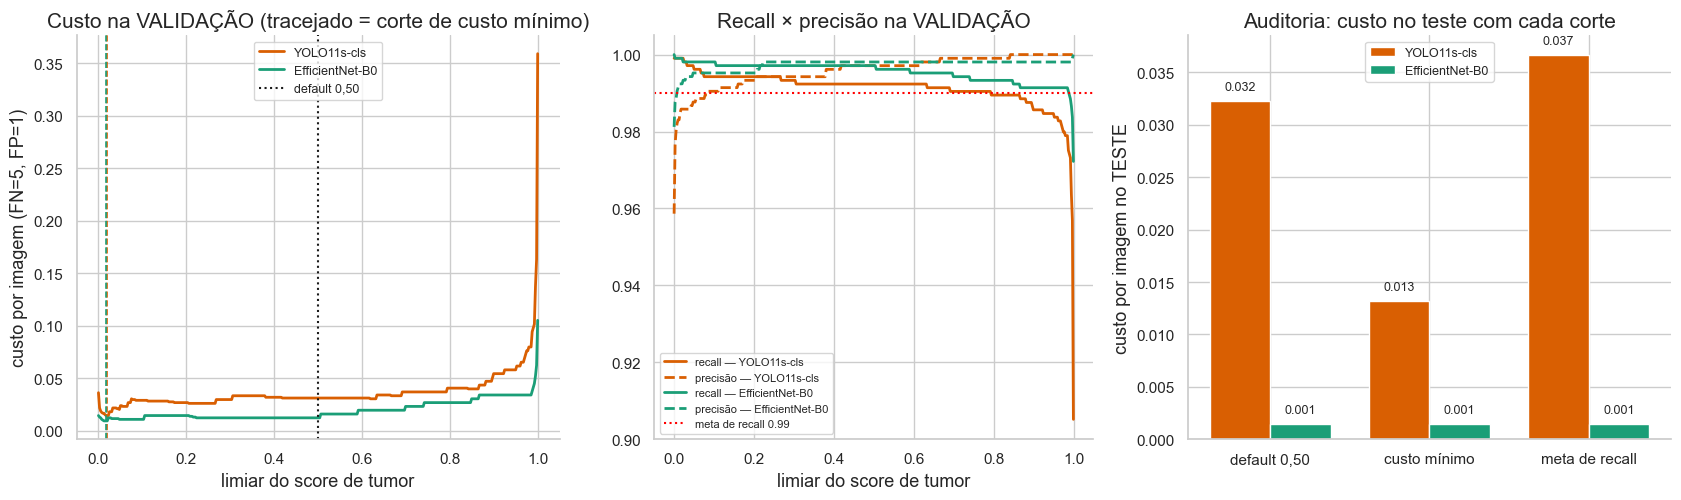

salvo: 09_limiar_custo_e_auditoria.png


In [14]:
yb = {s: (Y[s] != i_nt).astype(int) for s in ("val", "test")}; sc = {m: {s: 1 - PROB[m][s][:, i_nt] for s in ("val", "test")} for m in MODELOS}; gr = np.linspace(.0005, .9995, 400)
def cfn(y, s, t): pred = s >= t; fn, fp_ = int(((y == 1) & ~pred).sum()), int(((y == 0) & pred).sum()); return (CFN * fn + CFP * fp_) / len(y), fn, fp_
LIM = {}
for m in MODELOS:
    cv_ = np.array([cfn(yb["val"], sc[m]["val"], t)[0] for t in gr]); idx = np.where(cv_ <= cv_.min() + 1e-12)[0]; ts = float(gr[idx[len(idx) // 2]])
    rc_ = np.array([((sc[m]["val"] >= t) & (yb["val"] == 1)).sum() / yb["val"].sum() for t in gr]); ok_ = np.where(rc_ >= META_RECALL)[0]; tr_ = float(gr[ok_.max()]) if len(ok_) else np.nan
    r = dict(curva=cv_, t_star=ts, intervalo=(float(gr[idx.min()]), float(gr[idx.max()])), t_recall=tr_)
    for nome, t in (("default 0,50", .5), (f"custo mínimo ({ts:.2f})", ts), (f"meta de recall ({tr_:.2f})", tr_)):
        cv1, fn1, fp1 = cfn(yb["val"], sc[m]["val"], t); ct1, fn2, fp2 = cfn(yb["test"], sc[m]["test"], t); r[nome] = dict(custo_val=cv1, custo_test=ct1, fn_test=fn2, fp_test=fp2, t=t)
    LIM[m] = r
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})
for m in MODELOS:
    ax[0].plot(gr, LIM[m]["curva"], color=COR[m], lw=2, label=m); ax[0].axvline(LIM[m]["t_star"], color=COR[m], ls="--", lw=1.2)
ax[0].axvline(.5, color="k", ls=":", label="default 0,50"); ax[0].set_xlabel("limiar do score de tumor"); ax[0].set_ylabel(f"custo por imagem (FN={CFN}, FP={CFP})"); ax[0].set_title("Custo na VALIDAÇÃO (tracejado = corte de custo mínimo)"); ax[0].legend(fontsize=9)
for m in MODELOS:
    pr_ = [((sc[m]["val"] >= t) & (yb["val"] == 1)).sum() / max(1, (sc[m]["val"] >= t).sum()) for t in gr]; rc_ = [((sc[m]["val"] >= t) & (yb["val"] == 1)).sum() / yb["val"].sum() for t in gr]
    ax[1].plot(gr, rc_, color=COR[m], lw=2, label=f"recall — {m}"); ax[1].plot(gr, pr_, color=COR[m], lw=2, ls="--", label=f"precisão — {m}")
ax[1].axhline(META_RECALL, color="red", ls=":", label=f"meta de recall {META_RECALL}"); ax[1].set_ylim(.9, 1.005); ax[1].set_xlabel("limiar do score de tumor"); ax[1].set_title("Recall × precisão na VALIDAÇÃO"); ax[1].legend(fontsize=8, loc="lower left")
nomes_c = ["default 0,50", "custo mínimo", "meta de recall"]; x = np.arange(3); w = .38
for j, m in enumerate(MODELOS):
    vals = [LIM[m][k]["custo_test"] for k in [k for k in LIM[m] if isinstance(LIM[m][k], dict)]]; ax[2].bar(x + (j - .5) * w, vals, w, color=COR[m], label=m)
    for xi, v in zip(x + (j - .5) * w, vals): ax[2].text(xi, v + .001, f"{v:.3f}", ha="center", fontsize=9)
ax[2].set_xticks(x); ax[2].set_xticklabels(nomes_c); ax[2].set_ylabel("custo por imagem no TESTE"); ax[2].set_title("Auditoria: custo no teste com cada corte"); ax[2].legend(fontsize=9); plt.tight_layout()
for m in MODELOS:
    kk = [k for k in LIM[m] if isinstance(LIM[m][k], dict)]; NUM[f"limiar_custo_minimo_{m}"] = round(LIM[m]["t_star"], 3); NUM[f"limiar_meta_recall_{m}"] = round(LIM[m]["t_recall"], 3)
    NUM[f"custo_teste_default_{m}"] = round(LIM[m][kk[0]]["custo_test"], 4); NUM[f"custo_teste_escolhido_{m}"] = round(LIM[m][kk[1]]["custo_test"], 4); NUM[f"custo_val_escolhido_{m}"] = round(LIM[m][kk[1]]["custo_val"], 4)
    NUM[f"fn_teste_default_{m}"] = LIM[m][kk[0]]["fn_test"]; NUM[f"fn_teste_escolhido_{m}"] = LIM[m][kk[1]]["fn_test"]; NUM[f"fp_teste_default_{m}"] = LIM[m][kk[0]]["fp_test"]; NUM[f"fp_teste_escolhido_{m}"] = LIM[m][kk[1]]["fp_test"]
SENS_META = {m: float(((sc[m]["test"] >= LIM[m]["t_recall"]) & (yb["test"] == 1)).sum() / yb["test"].sum()) for m in MODELOS}
for m in MODELOS: NUM[f"sens_teste_corte_meta_recall_{m}"] = round(SENS_META[m], 4)
def lt(m): kk =[k for k in LIM[m] if isinstance(LIM[m][k], dict)]; d, e = LIM[m][kk[0]], LIM[m][kk[1]]; return f"{m}: corte de custo mínimo {LIM[m]['t_star']:.2f} (faixa {LIM[m]['intervalo'][0]:.2f}–{LIM[m]['intervalo'][1]:.2f}); no teste, custo {e['custo_test']:.3f} com esse corte contra {d['custo_test']:.3f} no default 0,50 (falsos negativos {e['fn_test']} contra {d['fn_test']}; falsos positivos {e['fp_test']} contra {d['fp_test']}); previsto na validação {e['custo_val']:.3f}"
salvar("09_limiar_custo_e_auditoria.png", "Escolha do limiar pelo custo do erro (na validação) e auditoria no teste",
       f"Custo por imagem (1 falso negativo = {CFN} falsos positivos) em função do limiar do score de tumor, calculado na validação; recall e precisão pelo limiar com a meta de recall; e o custo medido no teste com o corte padrão 0,50, o de custo mínimo e o da meta de recall.",
       "Aula 12: o 0,50 não é ótimo de nada; o corte vem do custo ou da meta, escolhido na validação, e o teste só audita, uma vez. Com modelos muito precisos, a curva de custo tem um platô largo: não se persegue o mínimo exato, e o centro do platô é uma escolha robusta.",
       f"{lt(NOME_Y)}. {lt(NOME_C)}. No corte da meta de recall (maior limiar que cumpre recall ≥ {META_RECALL} na validação) a sensibilidade no teste foi {SENS_META[NOME_Y]:.3f} (YOLO, corte {LIM[NOME_Y]['t_recall']:.2f}) e {SENS_META[NOME_C]:.3f} (CNN, corte {LIM[NOME_C]['t_recall']:.2f}): a meta é uma restrição justa na validação, mas sem folga para a oscilação do teste. Como os modelos erram pouco, o ganho sobre o 0,50 é pequeno na CNN e maior no YOLO; o que importa é o procedimento (escolher na validação, auditar no teste).")

## Figura 10 — Calibração: o que o modelo prometeu × o que aconteceu (Aula 12)
A Aula 12 monta o **reliability diagram** com `calibration_curve(..., n_bins=5, strategy="quantile")` e a tabela "prometeu → aconteceu". Se o número está torto, a regra é **trocar de modelo se houver um honesto**; a exceção é **corrigir a saída**, com dados que o modelo não viu (calibrar no treino é vazamento). Fazemos a exceção como experimento: **escalonamento por temperatura** ajustado na **validação** e medido no **teste**.

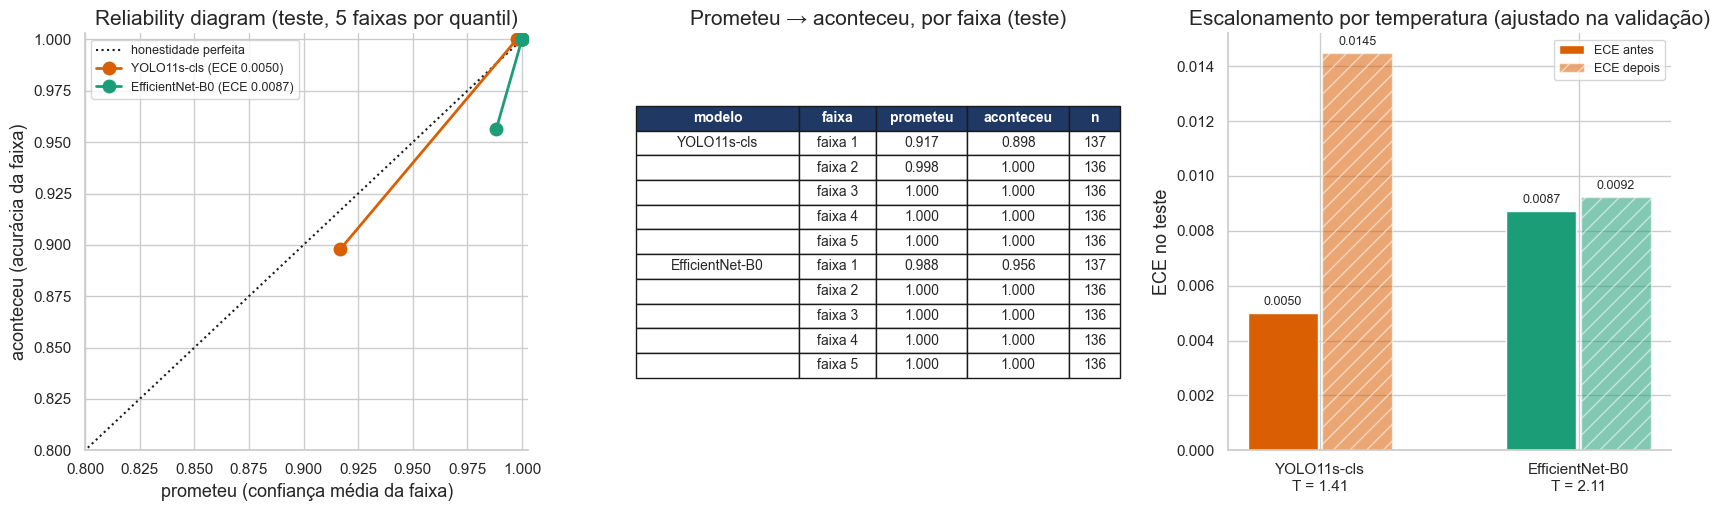

salvo: 10_calibracao.png


In [15]:
def faixas(m, s="test", nb=5):
    P = PROB[m][s]; conf, ok = P.max(1), PRED[m][s] == Y[s]; grupos = np.array_split(np.argsort(conf), nb); return [(conf[g].mean(), ok[g].mean(), len(g)) for g in grupos]
def nll_T(T, logp, y): z = logp / T; z = z - z.max(1, keepdims=True); lp = z - np.log(np.exp(z).sum(1, keepdims=True)); return -lp[np.arange(len(y)), y].mean()
def aplicaT(P, T): z = np.log(np.clip(P, 1e-12, 1)) / T; z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
TT, CAL = {}, {}
for m in MODELOS:
    lv = np.log(np.clip(PROB[m]["val"], 1e-12, 1)); TT[m] = minimize_scalar(lambda T: nll_T(T, lv, Y["val"]), bounds=(.05, 10), method="bounded").x; Pt = PROB[m]["test"]; Pc = aplicaT(Pt, TT[m])
    CAL[m] = dict(ece0=ece(Y["test"], Pt), ece1=ece(Y["test"], Pc), ll0=log_loss(Y["test"], Pt, labels=list(range(NC))), ll1=log_loss(Y["test"], Pc, labels=list(range(NC))), acc1=accuracy_score(Y["test"], Pc.argmax(1)))
fig, ax = plt.subplots(1, 3, figsize=(17, 5.3), gridspec_kw={"width_ratios": [1, 1.15, 1]}); ax[0].plot([0, 1], [0, 1], "k:", label="honestidade perfeita")
for m in MODELOS:
    fz = faixas(m); ax[0].plot([f[0] for f in fz], [f[1] for f in fz], "o-", color=COR[m], lw=2, ms=9, label=f"{m} (ECE {CAL[m]['ece0']:.4f})")
ax[0].set_xlim(.80, 1.003); ax[0].set_ylim(.80, 1.003); ax[0].set_xlabel("prometeu (confiança média da faixa)"); ax[0].set_ylabel("aconteceu (acurácia da faixa)"); ax[0].set_title("Reliability diagram (teste, 5 faixas por quantil)"); ax[0].legend(fontsize=9, loc="upper left")
ax[1].axis("off"); ax[1].set_title("Prometeu → aconteceu, por faixa (teste)"); linhas_t = []
for m in MODELOS:
    for k, (c_, a_, n_) in enumerate(faixas(m), 1): linhas_t.append([m if k == 1 else "", f"faixa {k}", f"{c_:.3f}", f"{a_:.3f}", n_])
tb = ax[1].table(cellText=linhas_t, colLabels=["modelo", "faixa", "prometeu", "aconteceu", "n"], loc="center", cellLoc="center", colWidths=[.32, .15, .18, .2, .1]); tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 1.45)
for (r_, c_), cell in tb.get_celld().items():
    if r_ == 0: cell.set_facecolor("#1F3864"); cell.set_text_props(color="white", fontweight="bold")
x = np.arange(2); w = .18
for j, (nm, key, h) in enumerate((("ECE antes", "ece0", ""), ("ECE depois", "ece1", "//"))):
    ax[2].bar(x + (j - .5) * w * 1.6, [CAL[m][key] for m in MODELOS], w * 1.5, color=[COR[m] for m in MODELOS], alpha=1 if j == 0 else .55, hatch=h, label=nm)
    for xi, m in zip(x + (j - .5) * w * 1.6, MODELOS): ax[2].text(xi, CAL[m][key] + .0003, f"{CAL[m][key]:.4f}", ha="center", fontsize=9)
ax[2].set_xticks(x); ax[2].set_xticklabels([f"{m}\nT = {TT[m]:.2f}" for m in MODELOS]); ax[2].set_ylabel("ECE no teste"); ax[2].set_title("Escalonamento por temperatura (ajustado na validação)"); ax[2].legend(fontsize=9); plt.tight_layout()
for m in MODELOS: NUM[f"ece_antes_{m}"] = round(CAL[m]["ece0"], 4); NUM[f"ece_depois_{m}"] = round(CAL[m]["ece1"], 4); NUM[f"temperatura_{m}"] = round(float(TT[m]), 3); NUM[f"logloss_antes_calibracao_{m}"] = round(CAL[m]["ll0"], 4); NUM[f"logloss_depois_calibracao_{m}"] = round(CAL[m]["ll1"], 4)
tdesc = lambda m: f"{m}: T = {TT[m]:.2f} ({'suaviza' if TT[m] > 1 else 'afia'} as probabilidades); no teste, ECE {CAL[m]['ece0']:.4f} → {CAL[m]['ece1']:.4f} e log-loss {CAL[m]['ll0']:.3f} → {CAL[m]['ll1']:.3f}"
salvar("10_calibracao.png", "Calibração: o modelo cumpre o que promete?",
       "Reliability diagram (confiança prometida × acurácia observada em 5 faixas com o mesmo número de imagens), a tabela 'prometeu → aconteceu' de cada faixa e o efeito de uma correção por temperatura ajustada na validação e medida no teste.",
       "Aula 12: pontos sobre a diagonal = número honesto; abaixo = confiança em excesso. A acurácia não muda ao calibrar (a ordem das classes é a mesma), muda o significado do número. Calibrar só vale quando a probabilidade entra numa conta (custo, corte, score lido por alguém); calibrar no treino seria vazamento.",
       f"{tdesc(NOME_Y)}. {tdesc(NOME_C)}. Os dois já saem bem calibrados (ECE ≤ 0,03). A temperatura melhora um pouco o log-loss, mas piora o ECE (YOLO {CAL[NOME_Y]['ece0']:.4f} → {CAL[NOME_Y]['ece1']:.4f}; CNN {CAL[NOME_C]['ece0']:.4f} → {CAL[NOME_C]['ece1']:.4f}) e a acurácia não muda; seguindo a regra da Aula 12 (não remendar quem já é honesto), não aplicamos a correção e entregamos os modelos como estão. A 1ª faixa (as imagens menos confiantes) é onde sobra algum excesso de confiança: prometeu {faixas(NOME_Y)[0][0]:.3f} e aconteceu {faixas(NOME_Y)[0][1]:.3f} no YOLO; {faixas(NOME_C)[0][0]:.3f} e {faixas(NOME_C)[0][1]:.3f} na CNN.")

## Figuras 12 e 13 — Mapas de calor (Grad-CAM) — **mantidos exatamente como estão**
As duas figuras aprovadas não são regeneradas: se os arquivos `12_gradcam_acertos.png` e `13_gradcam_erros.png` já existem na pasta, o notebook apenas os reutiliza e registra as legendas (variável `PRESERVAR`). Se forem apagados, o código abaixo os recria com a mesma semente e os mesmos modelos.

preservado (não regenerado): 12_gradcam_acertos.png


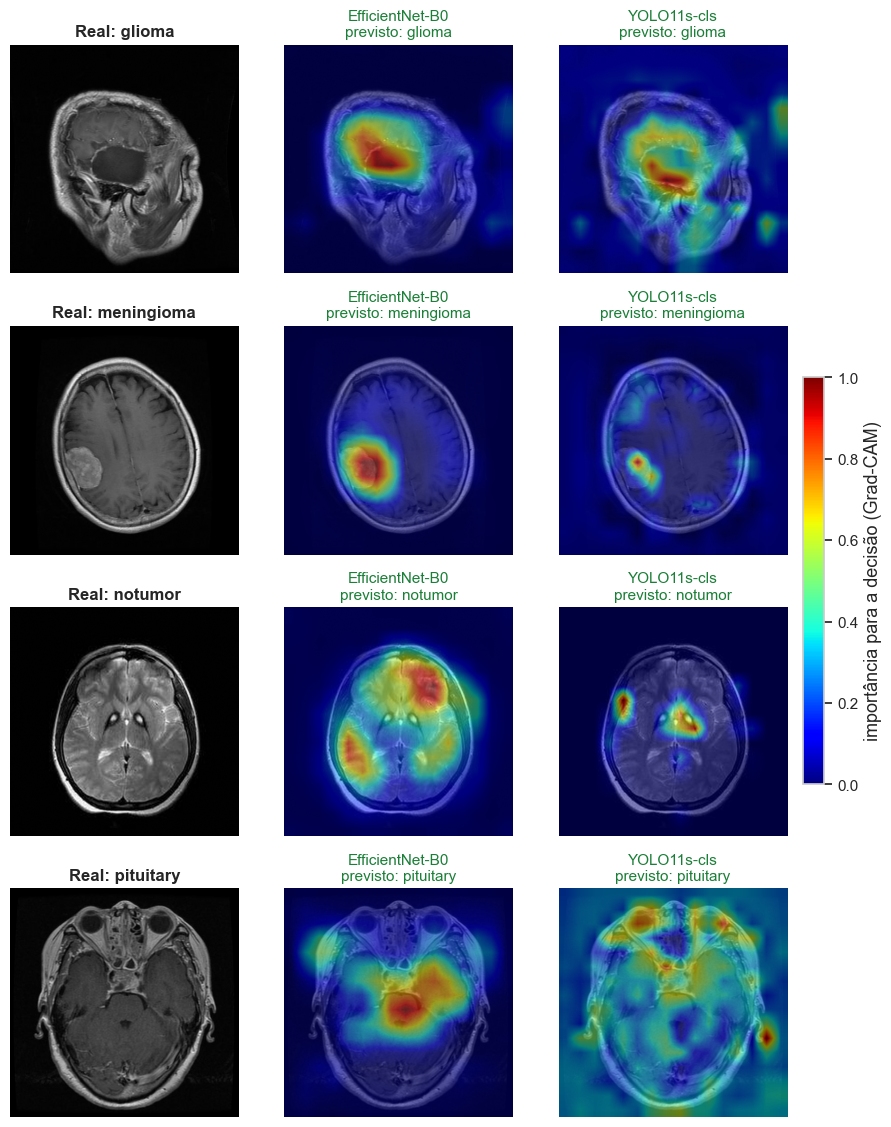

salvo: 12_gradcam_acertos.png


In [16]:
def painel(idxs, nome, titulo, mostra, ler, resultado, marca_erro=False):
    fig, ax = plt.subplots(len(idxs), 3, figsize=(10.5, 3.5 * len(idxs)))
    ax = np.atleast_2d(ax)
    for r, i in enumerate(idxs):
        im = Image.open(CAM["test"][i]).convert("RGB"); real = CLASSES[Y["test"][i]]; base = im.convert("L")
        ax[r, 0].imshow(base, cmap="gray"); ax[r, 0].set_title(f"Real: {real}", fontsize=12, fontweight="bold")
        for col, m in enumerate((NOME_C, NOME_Y), start=1):
            net, camada, tf = GC[m]; mapa, c = gradcam(net, camada, tf(im)); ax[r, col].imshow(base, cmap="gray"); ax[r, col].imshow(mapa, cmap="jet", alpha=.5, vmin=0, vmax=1)
            ax[r, col].set_title(f"{m}\nprevisto: {CLASSES[c]}", fontsize=11, color="#1a7f37" if CLASSES[c] == real else "#c62828")
        for a in ax[r]: a.axis("off")
    sm = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1)); cb = fig.colorbar(sm, ax=ax, fraction=.025, pad=.02); cb.set_label("importância para a decisão (Grad-CAM)")
    salvar(nome, titulo, mostra, ler, resultado)

rng = np.random.default_rng(SEED)
corretos = [int(rng.choice(np.where((Y["test"] == c) & (PRED[NOME_C]["test"] == c) & (PRED[NOME_Y]["test"] == c))[0])) for c in range(NC)]
try:
    painel(corretos, "12_gradcam_acertos.png", "Mapas de calor (Grad-CAM) em acertos — uma imagem por classe",
           "Imagem de RM original e, ao lado, o mapa de calor do que mais influenciou a decisão da CNN e do YOLO, para um exemplo correto de cada classe. Vermelho/amarelo = região mais importante.",
           "Esperamos que o calor se concentre na região anatômica relevante (lesão ou área da hipófise), e não em bordas, fundo escuro ou artefatos. É uma leitura qualitativa: não prova causalidade.",
           "Nos exemplos mostrados, a EfficientNet-B0 concentra o calor na lesão visível (glioma e meningioma) e na região central da base do crânio no caso pituitary; em 'notumor', onde não há lesão, o calor se espalha por várias regiões. O YOLO tem foco mais fragmentado, com pontos quentes também em bordas e regiões periféricas (ex.: pituitary), de interpretação menos clara. Os dois modelos acertam as 4 imagens. (Interpretação feita pela inspeção visual desta execução; releia se trocar as imagens.)")
except Exception as e: print("Grad-CAM (acertos) falhou:", type(e).__name__, str(e)[:300])

preservado (não regenerado): 13_gradcam_erros.png


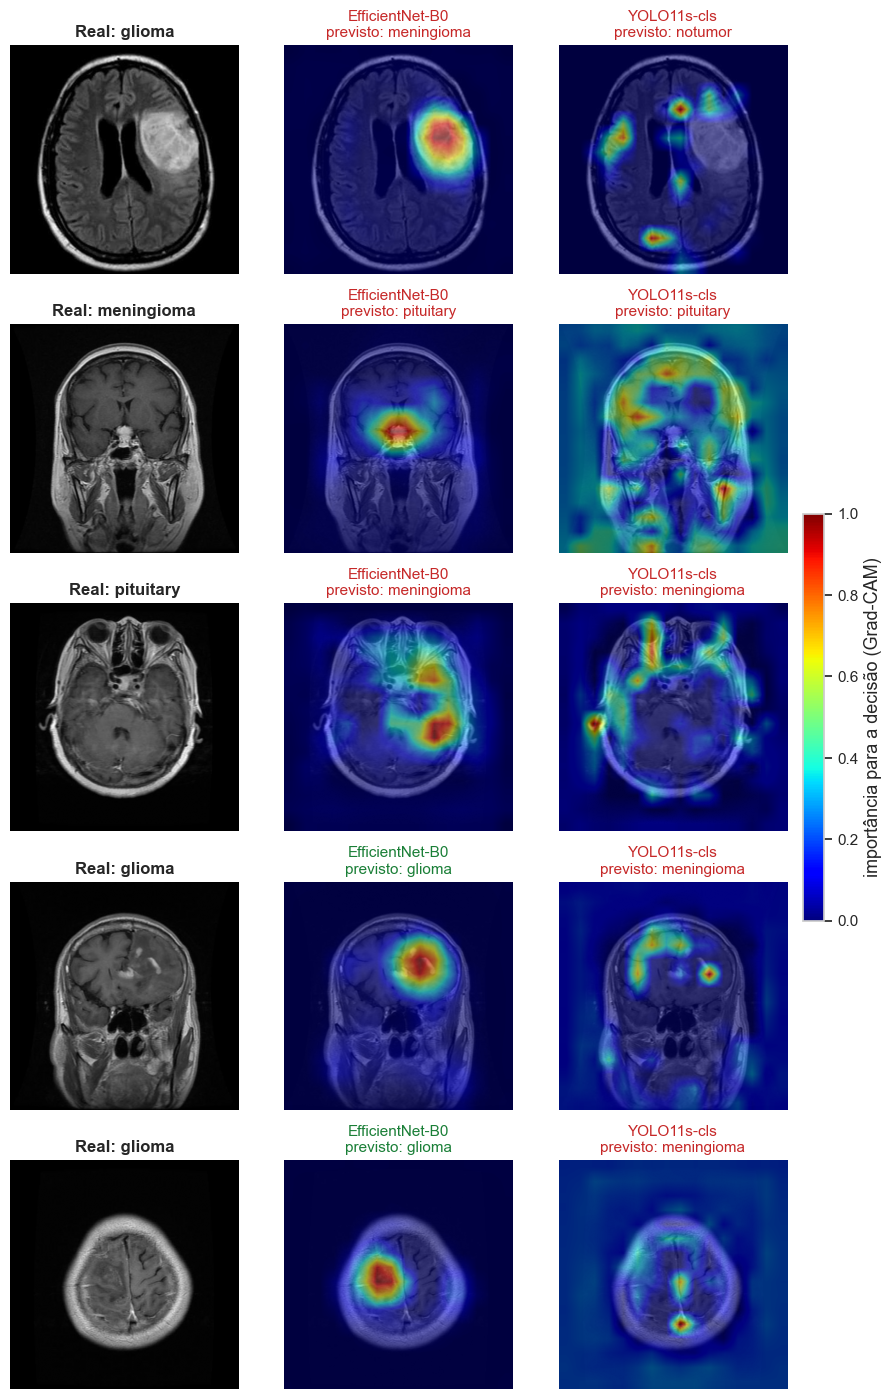

salvo: 13_gradcam_erros.png


In [17]:
e_y, e_c = PRED[NOME_Y]["test"] != Y["test"], PRED[NOME_C]["test"] != Y["test"]
ambos = np.where(e_y & e_c)[0]; um = np.where(e_y ^ e_c)[0]; sel_err = (list(ambos) + list(um))[:N_ERROS_GRADCAM]; NUM["erros_ambos_modelos"] = int(len(ambos)); NUM["erros_so_um_modelo"] = int(len(um))
try:
    painel(sel_err, "13_gradcam_erros.png", "Mapas de calor (Grad-CAM) em imagens erradas",
           "Imagens de teste em que pelo menos um modelo errou (primeiro as que os dois erram), com o mapa de calor de cada modelo e a classe prevista (verde = certo, vermelho = errado).",
           "Compare onde cada rede olhou quando errou: foco em região irrelevante ou difusa sugere falha de atenção; foco na lesão com classe errada sugere imagem ambígua entre tipos de tumor.",
           f"No teste, {len(ambos)} imagens foram erradas pelos dois modelos e {len(um)} por apenas um (erros complementares). Linha 1 (glioma): a CNN olha para a massa brilhante mas a chama de meningioma (confusão entre tipos de tumor), enquanto o YOLO dispersa a atenção fora da massa e prevê 'notumor' — um falso negativo. Linhas 2 e 3: ambos erram; na linha 2 a CNN foca a região central da base do crânio, perto da hipófise (hipótese de confusão por proximidade anatômica, não validada com especialista). Linhas 4 e 5: a CNN acerta com foco na lesão e o YOLO erra com atenção dispersa. (Interpretação feita pela inspeção visual desta execução; o painel mostra {len(sel_err)} imagens.)")
except Exception as e: print("Grad-CAM (erros) falhou:", type(e).__name__, str(e)[:300])

## Figura 14 — Checklist antivazamento e reprodutibilidade (Aulas 01 e 14)
O checklist da Aula 01 (preparação, avaliação) e a rotina da Aula 14 (**audite · remova · documente**), aplicados ao nosso projeto. Cada status vem de uma verificação feita neste notebook. A reprodutibilidade registra versões, hash dos pesos, semente e determinismo, e salva um **model card**.

In [18]:
def sha(p, bloco=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b_ in iter(lambda: f.read(bloco), b""): h.update(b_)
    return h.hexdigest()
hash_y, hash_c = sha(PESO_YOLO), sha(PESO_CNN)
manifest = hashlib.sha256("".join(sorted(f"{s}/{Path(p).name}:{hashlib.md5(Path(p).read_bytes()).hexdigest()}" for s in SPL3 for p in CAM[s])).encode()).hexdigest()

# determinismo: 2 execuções repetidas e comparação com as probabilidades guardadas
ims = [Image.open(CAM["test"][i]).convert("RGB") for i in range(32)]
def prever_n(m):
    if m == NOME_C:
        with torch.no_grad(): return torch.softmax(cnn(torch.stack([tf_aval(im) for im in ims]).to(device)), 1).cpu().numpy()
    return np.array([r.probs.data.cpu().numpy()[idx_y] for r in yolo.predict(ims, imgsz=IMG_SIZE, verbose=False, device=device.type)])
det = {m: float(np.abs(prever_n(m) - prever_n(m)).max()) for m in MODELOS}; vs_cache = {m: float(np.abs(prever_n(m) - PROB[m]["test"][:32]).max()) for m in MODELOS}
import yaml
args_y = yaml.safe_load((PASTA_YOLO_RUN / "args.yaml").read_text(encoding="utf-8")); seed_y = args_y.get("seed")
env = {"python": sys.version.split()[0], "torch": torch.__version__, "torchvision": __import__("torchvision").__version__, "ultralytics": __import__("ultralytics").__version__, "scikit-learn": __import__("sklearn").__version__, "numpy": np.__version__, "pandas": pd.__version__, "so": platform.platform(), "dispositivo": str(device)}
repro = dict(ambiente=env, sha256_pesos={NOME_Y: hash_y, NOME_C: hash_c}, manifesto_dataset_sha256=manifest, n_imagens=sum(len(DS[s]) for s in SPL3), semente_yolo=seed_y, semente_cnn=42, seed_avaliacao=SEED,
             determinismo_dif_max=det, dif_max_vs_cache=vs_cache, img_size=IMG_SIZE, classes=CLASSES)
(KIT / "reprodutibilidade.json").write_text(json.dumps(repro, ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps({k: repro[k] for k in ("ambiente", "determinismo_dif_max", "dif_max_vs_cache", "semente_yolo")}, ensure_ascii=False, indent=1))

{
 "ambiente": {
  "python": "3.14.0",
  "torch": "2.11.0+cpu",
  "torchvision": "0.26.0+cpu",
  "ultralytics": "8.4.194",
  "scikit-learn": "1.8.0",
  "numpy": "2.4.0",
  "pandas": "2.3.3",
  "so": "Windows-11-10.0.26100-SP0",
  "dispositivo": "cpu"
 },
 "determinismo_dif_max": {
  "YOLO11s-cls": 0.0,
  "EfficientNet-B0": 0.0
 },
 "dif_max_vs_cache": {
  "YOLO11s-cls": 2.2351741790771484e-08,
  "EfficientNet-B0": 0.0
 },
 "semente_yolo": 42
}


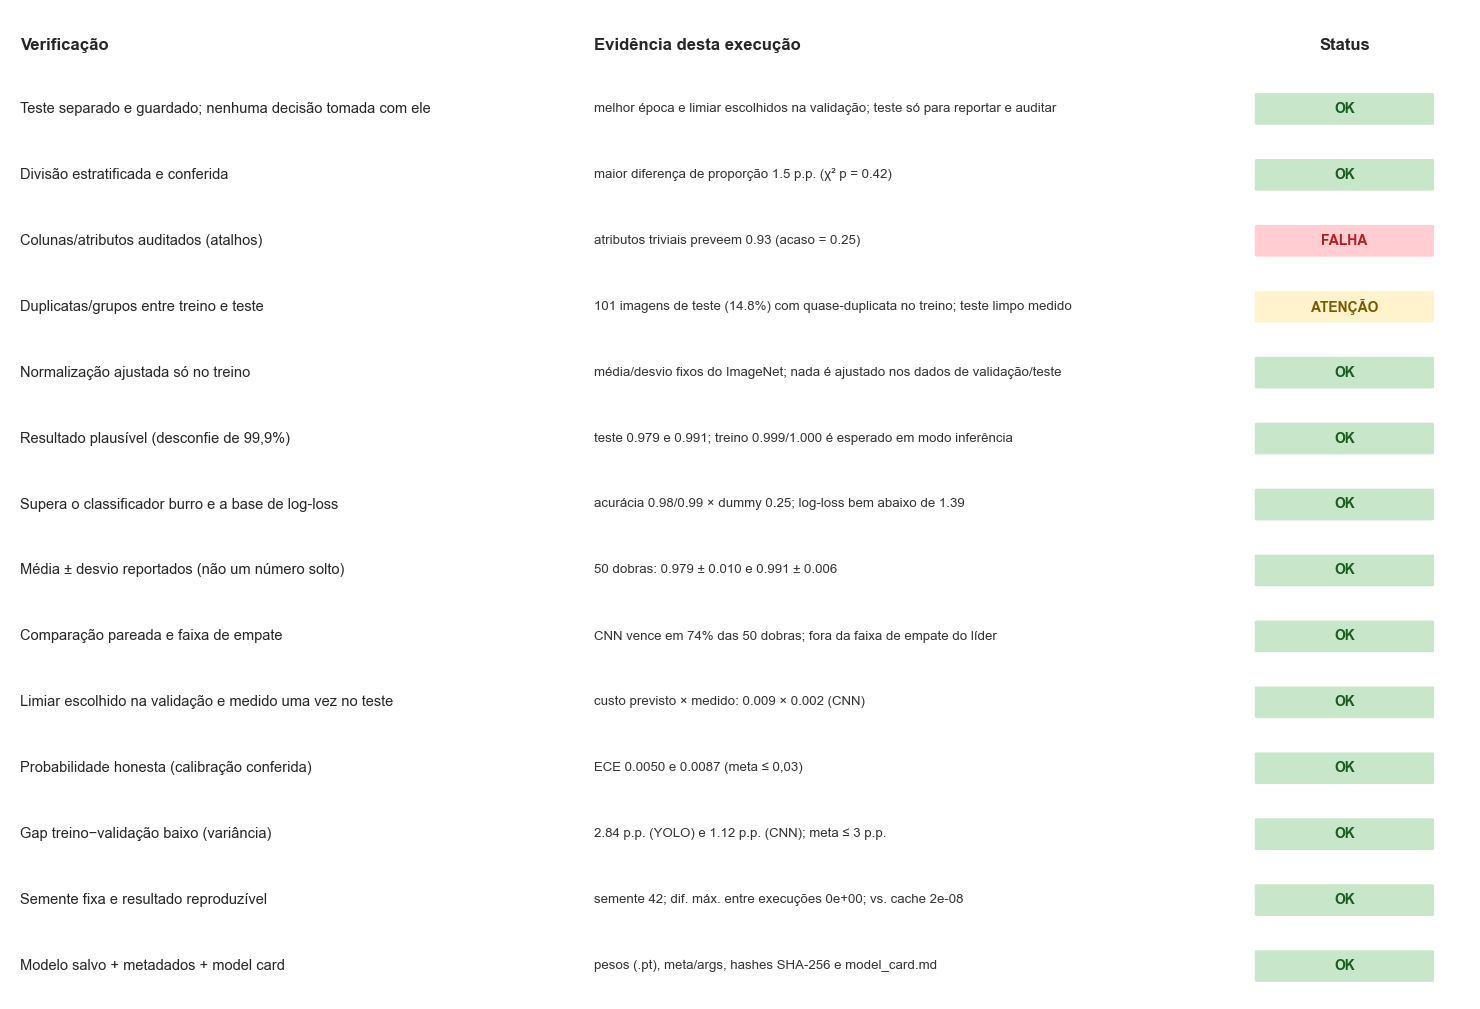

salvo: 14_checklist_antivazamento.png


In [19]:
acc_t = {m: acc(m, "test") for m in MODELOS}; g_tv = {m: acc(m, "train") - acc(m, "val") for m in MODELOS}
itens = [
 ("Teste separado e guardado; nenhuma decisão tomada com ele", "ok" , "melhor época e limiar escolhidos na validação; teste só para reportar e auditar", "Aula 01/05"),
 ("Divisão estratificada e conferida", "ok" if p_chi > .05 else "atencao", f"maior diferença de proporção {maxdev:.1f} p.p. (χ² p = {p_chi:.2f})", "Aula 05"),
 ("Colunas/atributos auditados (atalhos)", "ok" if acc_h < .4 else ("atencao" if acc_h < .6 else "falha"), f"atributos triviais preveem {acc_h:.2f} (acaso = {1/NC:.2f})", "Aula 14"),
 ("Duplicatas/grupos entre treino e teste", "ok" if dup_tt.mean() < .01 else "atencao", f"{dup_tt.sum()} imagens de teste ({100*dup_tt.mean():.1f}%) com quase-duplicata no treino; teste limpo medido", "Aula 06/14"),
 ("Normalização ajustada só no treino", "ok", "média/desvio fixos do ImageNet; nada é ajustado nos dados de validação/teste", "Aula 05"),
 ("Resultado plausível (desconfie de 99,9%)", "ok" if max(acc_t.values()) < .995 else "atencao", f"teste {acc_t[NOME_Y]:.3f} e {acc_t[NOME_C]:.3f}; treino {acc(NOME_Y,'train'):.3f}/{acc(NOME_C,'train'):.3f} é esperado em modo inferência", "Aula 01"),
 ("Supera o classificador burro e a base de log-loss", "ok" if min(acc_t.values()) > BS["Dummy (classe mais comum)"]["acc"] + .3 and max(BS[NOME_Y]["ll"], BS[NOME_C]["ll"]) < ll_prev else "falha", f"acurácia {acc_t[NOME_Y]:.2f}/{acc_t[NOME_C]:.2f} × dummy {BS['Dummy (classe mais comum)']['acc']:.2f}; log-loss bem abaixo de {ll_prev:.2f}", "Aula 02/03"),
 ("Média ± desvio reportados (não um número solto)", "ok", f"50 dobras: {mu[NOME_Y]:.3f} ± {sd[NOME_Y]:.3f} e {mu[NOME_C]:.3f} ± {sd[NOME_C]:.3f}", "Aula 06"),
 ("Comparação pareada e faixa de empate", "ok", f"{'CNN' if vit > der else 'YOLO'} vence em {100*max(vit, der):.0f}% das 50 dobras; " + ("empate técnico" if empate else "fora da faixa de empate do líder"), "Aula 12"),
 ("Limiar escolhido na validação e medido uma vez no teste", "ok", f"custo previsto × medido: {NUM['custo_val_escolhido_'+NOME_C]:.3f} × {NUM['custo_teste_escolhido_'+NOME_C]:.3f} (CNN)", "Aula 12"),
 ("Probabilidade honesta (calibração conferida)", "ok" if max(CAL[m]["ece0"] for m in MODELOS) <= .03 else "atencao", f"ECE {CAL[NOME_Y]['ece0']:.4f} e {CAL[NOME_C]['ece0']:.4f} (meta ≤ 0,03)", "Aula 12"),
 ("Gap treino−validação baixo (variância)", "ok" if max(g_tv.values()) <= .03 else "atencao", f"{100*g_tv[NOME_Y]:.2f} p.p. (YOLO) e {100*g_tv[NOME_C]:.2f} p.p. (CNN); meta ≤ 3 p.p.", "Aula 01/10"),
 ("Semente fixa e resultado reproduzível", "ok" if max(det.values()) <= 1e-5 and max(vs_cache.values()) < 1e-3 else "atencao", f"semente 42; dif. máx. entre execuções {max(det.values()):.0e}; vs. cache {max(vs_cache.values()):.0e}", "Aula 14"),
 ("Modelo salvo + metadados + model card", "ok", "pesos (.pt), meta/args, hashes SHA-256 e model_card.md", "Aula 14"),
]
(KIT / "checklist.json").write_text(json.dumps([dict(item=i[0], status=i[1], evidencia=i[2], aula=i[3]) for i in itens], ensure_ascii=False, indent=1), encoding="utf-8")
fig, ax = plt.subplots(figsize=(15, 0.62 * len(itens) + 1.6)); ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, len(itens) + 1)
for x_, t_ in ((.1, "Verificação"), (6.0, "Evidência desta execução"), (13.7, "Status")): ax.text(x_, len(itens) + .4, t_, fontweight="bold", fontsize=12, ha="left" if x_ < 13 else "center")
for r_, (nome, st, evid, aula) in enumerate(itens):
    y = len(itens) - r_ - .5; fill, fg, rot = sty[st]; ax.text(.1, y, nome, va="center", fontsize=10.5); ax.text(6.0, y, evid, va="center", fontsize=9.5, color="#333")
    ax.add_patch(mpatches.FancyBboxPatch((12.8, y - .22), 1.8, .44, boxstyle="round,pad=0.02", fc=fill, ec="none")); ax.text(13.7, y, rot, ha="center", va="center", fontsize=10, fontweight="bold", color=fg)
plt.tight_layout(); n_ok = sum(1 for i in itens if i[1] == "ok"); n_at = sum(1 for i in itens if i[1] == "atencao"); n_fa = sum(1 for i in itens if i[1] == "falha")
NUM.update(checklist_ok=n_ok, checklist_atencao=n_at, checklist_falha=n_fa, checklist_total=len(itens), determinismo_dif_max=max(det.values()))
com_atencao = "; ".join(i[0] for i in itens if i[1] != "ok") or "nenhum"
salvar("14_checklist_antivazamento.png", "Checklist antivazamento e reprodutibilidade (Aulas 01 e 14)",
       "Quatorze verificações da disciplina aplicadas ao projeto (teste guardado, estratificação, atalhos, duplicatas, normalização, plausibilidade, baseline, média ± desvio, comparação pareada, limiar, calibração, variância, reprodutibilidade, model card), cada uma com a evidência calculada neste notebook.",
       "Aula 14: o vazamento não dá erro, dá um resultado bom; a rotina é auditar, remover e documentar. OK = verificação passou; ATENÇÃO = vale registrar no relatório; FALHA = corrigir antes de confiar no número.",
       f"{n_ok} de {len(itens)} verificações OK, {n_at} com atenção e {n_fa} com falha. Falha: {'; '.join(i[0] for i in itens if i[1] == 'falha') or 'nenhuma'}. Atenção: {'; '.join(i[0] for i in itens if i[1] == 'atencao') or 'nenhuma'}. A falha (atributos triviais da imagem preveem ≈{100*acc_h:.0f}% das classes) é a principal ressalva do trabalho; as quase-duplicatas entre treino e teste tiveram o efeito medido no teste limpo.")

In [20]:
# ---- model card (Aula 14: "salvar o Pipeline inteiro + model card") ----
def mc(m):
    s = f"""## {m}
- **Teste ({len(Y['test'])} imagens):** acurácia {acc(m,'test'):.4f} · F1 macro {NUM['f1_macro_teste_'+m]:.4f} · AUC macro {NUM['auc_macro_teste_'+m]:.4f} · log-loss {NUM['logloss_teste_'+m]:.4f} · ECE {NUM['ece_antes_'+m]:.4f}
- **Teste limpo (sem quase-duplicatas, {int(LIMPO_T.sum())} imagens):** acurácia {acc_limpo[m]:.4f}
- **Média ± desvio em 50 dobras do teste:** {NUM['dobras_acc_media_'+m]:.4f} ± {NUM['dobras_acc_desvio_'+m]:.4f}
- **Visão clínica (tumor × sem tumor):** sensibilidade {NUM['sensibilidade_tumor_'+m]:.4f}, especificidade {NUM['especificidade_'+m]:.4f}, F2 {NUM['f2_tumor_'+m]:.4f}
- **Pior classe (recall):** {NUM['classe_menor_recall_'+m]} = {NUM['menor_recall_classe_'+m]:.4f}
- **Peso (SHA-256):** `{hash_y if m == NOME_Y else hash_c}`
"""
    return s
card = f"""# Model card — classificação de tumor cerebral em RM ({NOME_Y} e {NOME_C})

> Trabalho acadêmico. **Não é um dispositivo médico** e não deve apoiar diagnóstico real.

## Uso pretendido
Classificar imagens de ressonância magnética cerebral em 4 classes ({', '.join(CLASSES)}), como estudo comparativo de duas arquiteturas.

## Dados
- Conjunto *Tumor Cerebral* v1 (Roboflow, CC BY 4.0), {sum(len(DS[s]) for s in SPL3)} imagens 512×512: treino {len(DS['train'])}, validação {len(DS['val'])}, teste {len(DS['test'])} (divisão estratificada; χ² p = {p_chi:.2f}).
- {NUM['imagens_teste_quase_duplicata_treino']} imagens de teste ({NUM['pct_teste_quase_duplicata_treino']}%) têm quase-duplicata no treino; sem identificador de paciente.
- Manifesto do dataset (SHA-256 dos arquivos): `{manifest}`

## Treino
- {NOME_Y}: yolo11s-cls pré-treinado, {args_y.get('epochs')} épocas máx., AdamW, lr {args_y.get('lr0')}, batch {args_y.get('batch')}, imgsz {args_y.get('imgsz')}, semente {seed_y}.
- {NOME_C}: EfficientNet-B0 (torchvision, ImageNet), AdamW, lr 3e-4, batch 32, 512×512, semente 42, {meta['epocas_treinadas']} épocas.

## Desempenho (conjunto de teste)
{mc(NOME_Y)}
{mc(NOME_C)}
## Decisão
- Limiar de tumor escolhido pelo custo (FN = {CFN} × FP) na validação: YOLO {LIM[NOME_Y]['t_star']:.2f}, CNN {LIM[NOME_C]['t_star']:.2f}.
- Calibração (temperatura, ajustada na validação): T = {TT[NOME_Y]:.2f} (YOLO) e {TT[NOME_C]:.2f} (CNN).

## Limitações
- Validação interna (mesmo conjunto de origem); sem validação externa em outro hospital/scanner.
- Quase-duplicatas entre treino e teste; auditoria de atalhos: atributos triviais preveem {acc_h:.2f} (acaso {1/NC:.2f}).
- Uma execução de treino por modelo (sem variância entre treinos); curva de aprendizado não avaliada.
- Robustez a ruído, desfoque forte e compressão severa é limitada (ver notebook de validação completa).

## Reprodutibilidade
Ambiente: {env['python']}, torch {env['torch']}, ultralytics {env['ultralytics']}, scikit-learn {env['scikit-learn']}; dispositivo {env['dispositivo']}. Diferença máxima entre execuções repetidas: {max(det.values()):.0e}.
"""
(KIT / "model_card.md").write_text(card, encoding="utf-8"); print(card[:1200])

# Model card — classificação de tumor cerebral em RM (YOLO11s-cls e EfficientNet-B0)

> Trabalho acadêmico. **Não é um dispositivo médico** e não deve apoiar diagnóstico real.

## Uso pretendido
Classificar imagens de ressonância magnética cerebral em 4 classes (glioma, meningioma, notumor, pituitary), como estudo comparativo de duas arquiteturas.

## Dados
- Conjunto *Tumor Cerebral* v1 (Roboflow, CC BY 4.0), 6879 imagens 512×512: treino 4819, validação 1379, teste 681 (divisão estratificada; χ² p = 0.42).
- 101 imagens de teste (14.8%) têm quase-duplicata no treino; sem identificador de paciente.
- Manifesto do dataset (SHA-256 dos arquivos): `24859d45c130ff831b85f33283d958c068deb77555e1f9657af7b7905a6e8b73`

## Treino
- YOLO11s-cls: yolo11s-cls pré-treinado, 100 épocas máx., AdamW, lr 0.0003, batch 32, imgsz 512, semente 42.
- EfficientNet-B0: EfficientNet-B0 (torchvision, ImageNet), AdamW, lr 3e-4, batch 32, 512×512, semente 42, 100 épocas.

## Desempenho (conjunto de teste)
## YOL

## Exportar legendas e números-chave

In [21]:
ordem_f = ["01", "02", "03", "04", "05", "06", "07", "08", "09", "10", "12", "13", "14"]
LEG.sort(key=lambda l: ordem_f.index(l["arquivo"][:2]) if l["arquivo"][:2] in ordem_f else 99)
(KIT / "legendas.json").write_text(json.dumps(LEG, ensure_ascii=False, indent=1), encoding="utf-8")
nums = pd.DataFrame({"valor": pd.Series(NUM)}); nums.to_csv(KIT / "numeros_chave.csv", encoding="utf-8-sig"); display(nums.T.iloc[:, :40])
print(f"\n{len(LEG)} figuras em {FIG}")
for l in LEG: print(" -", l["arquivo"])

,pct_teste_quase_duplicata_treino,imagens_teste_quase_duplicata_treino,acc_teste_limpo_YOLO11s-cls,acc_teste_limpo_EfficientNet-B0,chi2_p_estratificacao,maior_desvio_proporcao_pp,razao_maior_menor_classe_treino,melhor_epoca_YOLO11s-cls,plato_inicio_YOLO11s-cls,otimismo_selecao_pp_YOLO11s-cls,...,acc_atalhos_gradboost_teste_limpo,atalhos_top1,atalhos_top2,atalhos_top3,f2_tumor_YOLO11s-cls,especificidade_YOLO11s-cls,sensibilidade_tumor_YOLO11s-cls,recall_macro_teste_YOLO11s-cls,menor_recall_classe_YOLO11s-cls,classe_menor_recall_YOLO11s-cls
valor,14.8,101,0.9772,0.9895,0.418,1.47,1.08,63,49,0.31,...,0.9175,desvio,borda superior,borda inferior,0.9931,0.9872,0.9924,0.9796,0.9602,meningioma



13 figuras em C:\Users\pedro.almeida\Downloads\Trabalho Faculdade\Kit_Apresentacao\figuras
 - 01_papeis_estratificacao.png
 - 02_curva_por_epoca.png
 - 03_comparacao_com_baselines.png
 - 04_auditoria_de_atalhos.png
 - 05_relatorio_de_classificacao.png
 - 06_roc_e_precisao_recall.png
 - 07_log_loss.png
 - 08_estabilidade_por_dobras.png
 - 09_limiar_custo_e_auditoria.png
 - 10_calibracao.png
 - 12_gradcam_acertos.png
 - 13_gradcam_erros.png
 - 14_checklist_antivazamento.png
